# 09 — Medium diagnosis, ROI geometry and matched-cost comparison (LEVIR-CD)

**Purpose:** Explain the gap between Medium's binary Component Recall and ROI Component Coverage, then compare Medium against Light at comparable coverage and under different downstream workloads. **No retraining. No GPU inference. No new crop/model implementation.**

This notebook **reuses the original 06 code** (byte-for-byte, with its SHA-256 checked against the original completed experiment), the existing project `satchange.semantic.roi.extract_rois`, and saved H08 validation results. Actual project caches are required.

**Primary research questions:**

1. Is Medium's weak component matching mainly associated with merged or oversized predicted regions, or with truly missed changes?
2. How much ROI coverage is gained from bounding-box/context expansion rather than from the underlying binary prediction?
3. At matched ROI coverage, does Medium need fewer crops or less total cropped area than Light? How sensitive is that finding to downstream inference cost?

**Design:** Use **validation only**, pair-aware bootstrap, exactly the original LEVIR ground-truth component rules. This is **exploratory analysis** following prior inspection of validation and test. It **cannot** isolate training-hyperparameter effects; retraining decisions follow from measured bottlenecks, not a causal conclusion about hyperparameters.

**Run All:** All enabled sections execute; no hidden optional seed-gate is needed. Outputs are written to `artifacts/hypothesis_tests/H09_medium_topology_matched_cost/`. The final cell exports a ZIP. There is no test-set evaluation in this notebook.

## 0. Configuration — default settings execute all experiments

In [1]:
from pathlib import Path
PROJECT_ROOT = Path('.')
V1_RUN = 'H1_H5_v1'
H08_RUN = 'H08_roi_model_selection_v2'
H08_RESULTS_ZIP = None  # Optional Path to H08_roi_model_selection_v2_results.zip if local H08 folder is missing.
OUT_NAME = 'H09_medium_topology_matched_cost'

RUN_TOPOLOGY = True              # Analyze actual Medium/Light probability maps, masks and components.
RUN_CROP_GEOMETRY = True         # Analyze actual project ROIs; assess margin-rescued changes and crop sizes.
RUN_MATCHED_COMPARISONS = True  # Matched coverage; paired bootstrap on original H08 per-image CSVs.
RUN_COST_SENSITIVITY = True      # Cost curves with labeled hypothetical WHAT time.
RUN_CASE_STUDIES = True          # Save small number of GT/prediction/ROI visualizations.

TOPOLOGY_THRESHOLDS = (0.35, 0.55, 0.70, 0.85, 0.95)
TOPOLOGY_VARIANTS = ('light_full','medium_full','light_resized','medium_resized')
# In H08, selected ROI configs vary in thresholds/context/min-area; choose here by H08 high coverage + low area.
TARGET_COVERAGE = {'full': 0.975, 'resized': 0.935}
MATCH_TOLERANCE = 0.005  # If two configs differ by >0.5 percentage points, report NOT matched.
BOOTSTRAP_REPS = 2000
BOOTSTRAP_SEED = 20261029
N_CASE_STUDIES = 3

# Only *illustrative* downstream WHAT inference scenarios; NOT actual measured latency.
DOWNSTREAM_MS_PER_CROP = (0.0, 1.0, 5.0, 10.0, 25.0, 50.0)
DOWNSTREAM_MS_PER_MPIXEL = (0.0, 2.0, 10.0)

print('Project root:', PROJECT_ROOT)
print('Executing topology:',RUN_TOPOLOGY,'ROI geometry:',RUN_CROP_GEOMETRY,
      'paired matched comparisons:',RUN_MATCHED_COMPARISONS,'cost sensitivity:',RUN_COST_SENSITIVITY)

Project root: .
Executing topology: True ROI geometry: True paired matched comparisons: True cost sensitivity: True


## 1. Reuse original 06 evaluation code — unchanged, SHA-256 verified

In [2]:
CORE_SOURCE = r'''"""Read-only LEVIR-CD inference and exploratory H1--H5 analysis.

Project adapter reviewed against the supplied levir_hypotheses_context.zip.
No training, downloads, writes to src/, or changes to final_models/.
"""
from __future__ import annotations

import copy
import gc
import hashlib
import itertools
import json
import math
import os
import platform
import re
import shutil
import subprocess
import sys
import time
import warnings
from collections import OrderedDict
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import Path
from typing import Any, Mapping
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import scipy
import PIL
import pandas as pd
import torch
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from torch.nn import functional as F

IMPLEMENTATION_VERSION = "levir-H1-H5-1.0.0"
VARIANTS = ("light_full", "light_resized", "medium_full", "medium_resized",
            "heavy_full", "heavy_resized")


@dataclass
class Settings:
    project_root: str
    run_name: str = "H1_H5_v1"
    dataset_root: str | None = None
    variants: tuple[str, ...] = VARIANTS
    device: str = "cuda:0"
    include_other_seeds: bool = False
    trust_own_seed_checkpoints: bool = False
    cpu_threads: int = 4
    validation_atol: float = 0.001
    connectivity: int = 2  # 2 = 8-neighbour connectivity in a 2D mask.
    size_quantiles: tuple[float, float] = (1 / 3, 2 / 3)
    iou_thresholds: tuple[float, ...] = (0.1, 0.25, 0.5)
    primary_iou: float = 0.5
    coverage_thresholds: tuple[float, ...] = (0.1, 0.25, 0.5)
    boundary_tolerances_px: tuple[int, ...] = (1, 2, 4)
    primary_boundary_px: int = 2
    recall_targets: tuple[float, ...] = (0.8, 0.9)
    recall_match_tolerance: float = 0.005
    threshold_grid: tuple[float, ...] = tuple(np.linspace(0, 1, 101).tolist())
    bootstrap_repetitions: int = 1000
    bootstrap_seed: int = 20261020
    cost_source: str = "remeasure"  # or "saved_benchmark"; CSV is never used as truth.
    benchmark_warmup: int = 20
    benchmark_repetitions: int = 100
    minimum_free_gib: float = 1.0
    # Monetary values are OPTIONAL user scenarios, not measured market prices.
    gpu_price_per_hour: float | None = None
    review_price_per_alert: float | None = None
    missed_component_price: float | None = None
    scenario_pairs: int = 1000
    minimum_object_recall: float | None = None
    maximum_false_alerts_per_pair: float | None = None
    maximum_forward_ms: float | None = None
    # A CSV mapping split,sample_id,cluster_id can replace image-pair bootstrap units.
    cluster_csv: str | None = None


def _json_value(x: Any) -> Any:
    if isinstance(x, dict):
        return {str(k): _json_value(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_json_value(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, np.ndarray):
        return _json_value(x.tolist())
    if isinstance(x, np.generic):
        return _json_value(x.item())
    if isinstance(x, float) and not math.isfinite(x):
        return None
    return x


def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


def write_json(path: Path, obj: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + f".{os.getpid()}.tmp")
    tmp.write_text(json.dumps(_json_value(obj), ensure_ascii=False, indent=2,
                              sort_keys=True, allow_nan=False), encoding="utf-8")
    tmp.replace(path)


def digest(obj: Any) -> str:
    return hashlib.sha256(json.dumps(_json_value(obj), sort_keys=True,
                                     ensure_ascii=False).encode()).hexdigest()


def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(8 << 20), b""):
            h.update(block)
    return h.hexdigest()


def safe_div(a: float, b: float) -> float:
    return float(a / b) if b > 0 else float("nan")


def metric_counts(pred: np.ndarray, gt: np.ndarray) -> dict[str, int]:
    if pred.shape != gt.shape or pred.dtype != bool or gt.dtype != bool:
        raise ValueError("Expected aligned 2-D boolean masks.")
    tp = int(np.count_nonzero(pred & gt))
    fp = int(np.count_nonzero(pred & ~gt))
    pos = int(gt.sum())
    return {"tp": tp, "fp": fp, "fn": pos - tp,
            "tn": gt.size - pos - fp}


def binary_metrics(c: Mapping[str, float]) -> dict[str, float]:
    tp, fp, fn = c["tp"], c["fp"], c["fn"]
    return {"pixel_precision": safe_div(tp, tp + fp),
            "pixel_recall": safe_div(tp, tp + fn),
            "pixel_f1": safe_div(2 * tp, 2 * tp + fp + fn),
            "pixel_iou": safe_div(tp, tp + fp + fn)}


def _tag(x: float) -> str:
    return f"{round(100 * x):03d}"


def _threshold_key(t: float) -> str:
    return hashlib.sha256(np.float32(t).tobytes()).hexdigest()[:12]


def boundary(mask: np.ndarray) -> np.ndarray:
    return mask & ~ndi.binary_erosion(mask, structure=np.ones((3, 3), bool),
                                      border_value=0)


def _distance_to(mask: np.ndarray) -> np.ndarray:
    if not mask.any():
        return np.full(mask.shape, np.inf, dtype=np.float32)
    return ndi.distance_transform_edt(~mask)


def inner_band(mask: np.ndarray, width: int) -> np.ndarray:
    return mask & ~ndi.binary_erosion(mask, structure=np.ones((3, 3), bool),
                                      iterations=width, border_value=0)


def match_components(gt_labels: np.ndarray, pred_labels: np.ndarray,
                     gt_areas: np.ndarray, pred_areas: np.ndarray,
                     iou_thresholds: tuple[float, ...]) -> tuple[dict, dict]:
    """One-to-one max-cardinality matching, then max IoU among such matchings.

    The matrix includes only IDs participating in an eligible IoU edge; tiny
    unrelated predictions still count as unmatched predictions, never disappear.
    """
    ng, npred = len(gt_areas) - 1, len(pred_areas) - 1
    overlap = (gt_labels > 0) & (pred_labels > 0)
    if overlap.any():
        codes = (gt_labels[overlap].astype(np.int64) * (npred + 1)
                 + pred_labels[overlap])
        codes, intersections = np.unique(codes, return_counts=True)
        gi, pi = codes // (npred + 1), codes % (npred + 1)
        ious = intersections / (gt_areas[gi] + pred_areas[pi] - intersections)
    else:
        gi = pi = np.array([], dtype=np.int64)
        ious = np.array([], dtype=float)
    info = {
        "gt_with_multiple_overlapping_pred_components": int(
            np.count_nonzero(np.bincount(gi, minlength=ng + 1)[1:] > 1)),
        "pred_components_overlapping_multiple_gt": int(
            np.count_nonzero(np.bincount(pi, minlength=npred + 1)[1:] > 1)),
    }
    found = {}
    for threshold in iou_thresholds:
        eligible = ious >= threshold
        gids, pids = np.unique(gi[eligible]), np.unique(pi[eligible])
        pairs = {}
        if len(gids) and len(pids):
            if len(gids) * len(pids) > 10_000_000:
                raise MemoryError("Component matching matrix too large; inspect fragmented masks.")
            weight = np.zeros((len(gids), len(pids)), dtype=np.float64)
            rr, cc = np.searchsorted(gids, gi[eligible]), np.searchsorted(pids, pi[eligible])
            # Total tie-breaking contribution < 1: one extra match always wins.
            weight[rr, cc] = 1 + ious[eligible] / (min(len(gids), len(pids)) + 1)
            r, c = linear_sum_assignment(weight, maximize=True)
            keep = weight[r, c] > 0
            for ri, ci in zip(r[keep], c[keep]):
                pairs[int(gids[ri])] = (int(pids[ci]), float(
                    (weight[ri, ci] - 1) * (min(len(gids), len(pids)) + 1)))
        found[threshold] = pairs
    return found, info


def exact_threshold_counts(scores: np.ndarray, gt: np.ndarray,
                           thresholds: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Exact counts on a predeclared grid, no lossy score histogram/rounding."""
    thresholds = thresholds.astype(np.float32)
    index = np.searchsorted(thresholds, scores.ravel(), side="right")
    positive = np.bincount(index[gt.ravel()], minlength=len(thresholds) + 1)
    negative = np.bincount(index[~gt.ravel()], minlength=len(thresholds) + 1)
    return np.cumsum(positive[::-1])[::-1][1:], np.cumsum(negative[::-1])[::-1][1:]


def pair_counts(a: np.ndarray, b: np.ndarray, gt: np.ndarray) -> dict:
    common = a & b
    union = a | b
    return {
        "n_positive": int(gt.sum()), "tp_a": int((a & gt).sum()),
        "tp_b": int((b & gt).sum()), "common_tp": int((common & gt).sum()),
        "a_only_tp": int((a & ~b & gt).sum()),
        "b_only_tp": int((b & ~a & gt).sum()),
        "common_fn": int((~union & gt).sum()),
        "fp_a": int((a & ~gt).sum()), "fp_b": int((b & ~gt).sum()),
        "common_fp": int((common & ~gt).sum()),
        "tp_or": int((union & gt).sum()), "fp_or": int((union & ~gt).sum()),
        "prediction_intersection": int(common.sum()), "prediction_union": int(union.sum()),
    }


def complementarity(c: Mapping[str, float]) -> dict:
    n, best = c["n_positive"], max(c["tp_a"], c["tp_b"])
    return {
        "jaccard_tp": safe_div(c["common_tp"], c["tp_or"]),
        "jaccard_fp": safe_div(c["common_fp"], c["fp_or"]),
        "jaccard_prediction": safe_div(c["prediction_intersection"], c["prediction_union"]),
        "recall_a": safe_div(c["tp_a"], n), "recall_b": safe_div(c["tp_b"], n),
        "precision_a": safe_div(c["tp_a"], c["tp_a"] + c["fp_a"]),
        "precision_b": safe_div(c["tp_b"], c["tp_b"] + c["fp_b"]),
        "recall_or": safe_div(c["tp_or"], n),
        "precision_or": safe_div(c["tp_or"], c["tp_or"] + c["fp_or"]),
        "extra_tp_vs_best": c["tp_or"] - best,
        "delta_recall": safe_div(c["tp_or"] - best, n),
        "complementarity_gain": safe_div(c["tp_or"] - best, n - best),
        "cg_denominator": n - best,
        "recovery_of_a_fn_by_b": safe_div(c["b_only_tp"], n - c["tp_a"]),
        "recovery_of_b_fn_by_a": safe_div(c["a_only_tp"], n - c["tp_b"]),
    }


def pareto_flags(df: pd.DataFrame, maximize: list[str], minimize: list[str]) -> np.ndarray:
    values = np.column_stack([*[df[c].to_numpy(float) for c in maximize],
                              *[-df[c].to_numpy(float) for c in minimize]])
    finite = np.isfinite(values).all(axis=1)
    flags = np.zeros(len(df), dtype=bool)
    for i in np.flatnonzero(finite):
        other = values[finite]
        flags[i] = not np.any(np.all(other >= values[i], axis=1)
                              & np.any(other > values[i], axis=1))
    return flags


class Experiment:
    def __init__(self, settings: Settings):
        self.cfg = settings
        self.root = Path(settings.project_root).expanduser().resolve()
        if not (self.root / "src/satchange/models/factory.py").is_file():
            raise FileNotFoundError(f"Not the project root: {self.root}")
        if not re.fullmatch(r"[A-Za-z0-9_-]+", settings.run_name):
            raise ValueError("run_name must contain only ASCII letters, digits, '-' and '_'.")
        if not settings.variants or len(set(settings.variants)) != len(settings.variants):
            raise ValueError("Select a non-empty set of distinct variants.")
        for name in ("iou_thresholds", "coverage_thresholds", "recall_targets"):
            values = getattr(settings, name)
            if not values or any(not math.isfinite(x) or not 0 < x <= 1 for x in values):
                raise ValueError(f"{name} must contain values in (0,1].")
            if len({_tag(x) for x in values}) != len(values):
                raise ValueError(f"{name}: values need distinct integer-percentage labels.")
        if settings.cpu_threads < 1 or settings.scenario_pairs < 1:
            raise ValueError("cpu_threads and scenario_pairs must be positive.")
        if not 0 < settings.size_quantiles[0] <= settings.size_quantiles[1] < 1:
            raise ValueError("Invalid size quantiles.")
        if any(r < 1 or int(r) != r for r in settings.boundary_tolerances_px):
            raise ValueError("Boundary tolerances must be positive integer native pixels.")
        if settings.connectivity not in (1, 2):
            raise ValueError("connectivity must be 1 (4 neighbours) or 2 (8 neighbours).")
        if settings.primary_iou not in settings.iou_thresholds:
            raise ValueError("primary_iou must be in iou_thresholds.")
        if settings.primary_boundary_px not in settings.boundary_tolerances_px:
            raise ValueError("primary_boundary_px must be in boundary_tolerances_px.")
        if settings.cost_source not in ("remeasure", "saved_benchmark"):
            raise ValueError("cost_source must be remeasure or saved_benchmark.")
        if settings.include_other_seeds and not settings.trust_own_seed_checkpoints:
            raise ValueError("Full seed checkpoints require explicit trust_own_seed_checkpoints=True.")
        if settings.bootstrap_repetitions < 100:
            warnings.warn("Fewer than 100 bootstrap replicates: debugging only, not a stable CI.")
        if settings.benchmark_repetitions < 1 or settings.benchmark_warmup < 0:
            raise ValueError("Invalid benchmark repetition counts.")
        for name in ("gpu_price_per_hour", "review_price_per_alert", "missed_component_price"):
            v = getattr(settings, name)
            if v is not None and (not math.isfinite(v) or v < 0):
                raise ValueError(f"{name} must be nonnegative or None.")
        self.device = torch.device(settings.device)
        if self.device.type == "cuda":
            if not torch.cuda.is_available():
                raise RuntimeError("CUDA unavailable. Choose the project's GPU kernel or set device='cpu'.")
            if self.device.index is None:
                self.device = torch.device("cuda:0")
            if self.device.index >= torch.cuda.device_count():
                raise ValueError("Requested CUDA device is not visible.")
        torch.set_num_threads(settings.cpu_threads)
        src = str(self.root / "src")
        if src not in sys.path:
            sys.path.insert(0, src)
        import satchange
        loaded = Path(satchange.__file__).resolve()
        if not loaded.is_relative_to(self.root / "src"):
            raise RuntimeError(f"Wrong satchange imported from {loaded}. Restart kernel in Research I.")
        from satchange.data.levir_cd import LEVIRCDDataset
        from satchange.models import create_change_model
        from satchange.final_benchmark import _runtime, _load_checkpoint, _instantiate
        self.Dataset = LEVIRCDDataset
        self.create_model = create_change_model
        self.runtime = _runtime  # Reuse the project's FP32/TF32 runtime controls.
        self.project_load_checkpoint = _load_checkpoint
        self.project_instantiate = _instantiate
        self.dataset_root = Path(settings.dataset_root or self.root / "data/LEVIR-CD").expanduser().resolve()
        self.datasets = {s: self.Dataset(self.dataset_root, s, None, transform=None)
                         for s in ("val", "test")}
        self.out = self.root / "artifacts/hypothesis_tests" / settings.run_name
        self.reports = self.out / "reports"
        self.reports.mkdir(parents=True, exist_ok=True)
        self.cache = self.out / "cache"
        self.cache.mkdir(exist_ok=True)
        self.gt_structure = ndi.generate_binary_structure(2, settings.connectivity)
        self.specs = self._specs()
        self.spec_by_id = {s["run_id"]: s for s in self.specs}
        self.primary = [s for s in self.specs if s["primary"]]
        self.source_manifest = {
            str(p.relative_to(self.root)): sha256_file(p)
            for p in sorted((self.root / "src/satchange").rglob("*.py"))}
        self.cluster_map = self._clusters()
        print("Hashing validation/test inputs for cache integrity (no test metrics)...", flush=True)
        self.data_manifest = self._data_manifest()
        self.protocol = {
            "implementation": IMPLEMENTATION_VERSION,
            "implementation_sha256": globals().get("IMPLEMENTATION_SHA256") or (sha256_file(Path(__file__)) if "__file__" in globals() else IMPLEMENTATION_VERSION),
            "settings": asdict(settings), "sources": self.source_manifest,
            "specs": self.specs, "data_manifest": self.data_manifest,
            "cluster_map": self.cluster_map,
            "environment": {"python": platform.python_version(), "torch": str(torch.__version__),
                            "numpy": np.__version__, "pandas": pd.__version__,
                            "scipy": scipy.__version__, "Pillow": PIL.__version__,
                            "cudnn": torch.backends.cudnn.version(),
                            "deterministic_algorithms": torch.are_deterministic_algorithms_enabled(),
                            "cuda": torch.version.cuda, "device": str(self.device),
                            "gpu": torch.cuda.get_device_name(self.device)
                            if self.device.type == "cuda" else None},
            "common_grid": "native GT; float32 sigmoid scores; bilinear upsample before >= threshold; align_corners=False",
            "scope": "post-hoc exploratory inference; no new architecture-causal claim",
        }
        self.signature = digest(self.protocol)
        manifest_path = self.out / "run_manifest.json"
        if manifest_path.exists() and read_json(manifest_path)["signature"] != self.signature:
            raise RuntimeError("Run inputs/code/settings changed. Choose a NEW run_name; old caches are preserved.")
        if not manifest_path.exists():
            write_json(manifest_path, {"signature": self.signature, "protocol": self.protocol,
                                      "created_utc": datetime.now(timezone.utc).isoformat()})
        self._audit()
        self.plan = read_json(self.out / "protocol_frozen.json") if (self.out / "protocol_frozen.json").exists() else None
        print(f"Output: {self.out}\nModels/checkpoints: {len(self.specs)}; primary pipelines: {len(self.primary)}")
        self._storage_check()

    def _specs(self) -> list[dict]:
        result = []
        for variant in self.cfg.variants:
            if variant not in VARIANTS:
                raise ValueError(f"Unknown variant: {variant}")
            folder = self.root / "artifacts/final_models" / variant
            meta = read_json(folder / "metadata.json")
            val = read_json(folder / "validation_results.json")
            if not {"model_name", "model_parameters", "image_size", "deployment_seed", "deployment_threshold"} <= meta.keys():
                raise ValueError(f"Incomplete metadata: {folder}")
            dep = int(meta["deployment_seed"])
            rows = {int(r["seed"]): r for r in val["results"]}
            available = sorted(int(p.name.split("_")[1]) for p in folder.glob("seed_*_best.pt"))
            seeds = [dep] + ([s for s in available if s != dep] if self.cfg.include_other_seeds else [])
            for seed in seeds:
                primary = seed == dep
                file = folder / ("deployment_weights.pt" if primary else f"seed_{seed}_best.pt")
                if not file.is_file():
                    raise FileNotFoundError(file)
                if seed not in rows:
                    raise ValueError(f"No validation record for {variant} seed {seed}")
                row = rows[seed]
                threshold = float(meta["deployment_threshold"] if primary else row["validation_threshold"])
                if not 0 < threshold < 1:
                    raise ValueError("Saved thresholds must be in (0,1).")
                if abs(threshold - float(row["validation_threshold"])) > 1e-9:
                    raise ValueError(f"Threshold conflict in {variant}/{seed}")
                image_size = meta["image_size"]  # Respect Medium Full's stored 1024, not an invented None.
                if variant.endswith("resized") and image_size != 256:
                    raise ValueError(f"Unexpected resized geometry for {variant}")
                if variant.endswith("full") and image_size not in (None, 1024):
                    raise ValueError(f"Unexpected full geometry for {variant}")
                result.append({"variant": variant, "run_id": f"{variant}__s{seed}",
                    "family": variant.split("_")[0], "resolution": variant.split("_")[1],
                    "seed": seed, "primary": primary, "image_size": image_size,
                    "model_name": meta["model_name"], "model_parameters": meta["model_parameters"],
                    "saved_threshold": threshold, "weight_file": str(file),
                    "weight_sha256": sha256_file(file),
                    "metadata_sha256": sha256_file(folder / "metadata.json"),
                    "validation_sha256": sha256_file(folder / "validation_results.json"),
                    "benchmark_sha256": sha256_file(folder / "benchmark.json"),
                    "expected_validation_f1": row["validation_f1"],
                    "expected_validation_iou": row["validation_iou"],
                    "expected_validation_pairs": val.get("number_of_pairs"),
                    "available_seed_files": available})
        return result

    def _clusters(self) -> dict:
        if self.cfg.cluster_csv is None:
            return {}
        path = Path(self.cfg.cluster_csv).expanduser()
        df = pd.read_csv(path, dtype=str)
        if not {"split", "sample_id", "cluster_id"} <= set(df):
            raise ValueError("cluster_csv needs split,sample_id,cluster_id columns.")
        if df.duplicated(["split", "sample_id"]).any() or df.isna().any().any():
            raise ValueError("Duplicate or missing cluster identifiers.")
        mapping = {f"{r.split}/{r.sample_id}": r.cluster_id for r in df.itertuples()}
        for split, ds in self.datasets.items():
            for sid in ds.sample_ids:
                if f"{split}/{sid}" not in mapping:
                    raise ValueError(f"Missing cluster for {split}/{sid}")
        return mapping

    def _data_manifest(self) -> dict:
        result = {}
        pair_hashes = {}
        for split, ds in self.datasets.items():
            result[split] = []
            pair_hashes[split] = set()
            for sid in ds.sample_ids:
                row = {"sample_id": sid}
                hashes = []
                for key, files in (("A", ds.before_files), ("B", ds.after_files), ("label", ds.label_files)):
                    p = files[sid]
                    h = sha256_file(p)
                    row[key] = {"file": str(p), "bytes": p.stat().st_size, "sha256": h}
                    hashes.append(h)
                pair_hashes[split].add(tuple(hashes[:2]))
                result[split].append(row)
        if pair_hashes["val"] & pair_hashes["test"]:
            raise ValueError("Identical RGB pairs detected in validation and test. Resolve split leakage first.")
        return result

    def _audit(self) -> None:
        table = pd.DataFrame([{k: s[k] for k in ("run_id", "variant", "seed", "primary", "image_size",
            "model_name", "saved_threshold", "available_seed_files")} | {"parameters": json.dumps(s["model_parameters"])}
                                for s in self.specs])
        table.to_csv(self.reports / "inventory.csv", index=False)
        issues = []
        for family in ("light", "medium", "heavy"):
            group = [s for s in self.primary if s["family"] == family]
            if len(group) == 2 and group[0]["model_parameters"] != group[1]["model_parameters"]:
                issues.append(f"{family}: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.")
        for s in self.primary:
            if len(s["available_seed_files"]) < 2:
                issues.append(f"{s['variant']}: only one seed file; no estimate of training-seed variance.")
        csv = self.root / "artifacts/final_models/final_models_metrics.csv"
        if csv.exists():
            original = pd.read_csv(csv)
            original.to_csv(self.reports / "historical_metrics_csv_NOT_USED.csv", index=False)
            if "f1_key" in original and not original["f1_key"].eq("test_f1").all():
                issues.append("final_models_metrics.csv mixes validation/test fields. It is NOT used for evaluation or model ranking.")
        old_cost = self.root / "artifacts/final_models/final_models_gpu_cost.csv"
        costs = []
        if old_cost.exists():
            c = pd.read_csv(old_cost)
            for s in self.primary:
                b = read_json(self.root / "artifacts/final_models" / s["variant"] / "benchmark.json")
                row = c.loc[c["model"] == s["variant"]]
                costs.append({"variant": s["variant"], "benchmark_json_ms": b.get("latency_ms_per_pair"),
                    "cost_csv_ms": float(row.iloc[0]["latency_ms"]) if len(row) else np.nan})
            pd.DataFrame(costs).to_csv(self.reports / "historical_cost_discrepancies.csv", index=False)
            issues.append("Saved cost CSV and per-model benchmark JSON are separate measurements; do not mix their protocols. H5 defaults to one fresh common forward-only benchmark.")
        issues += ["Connected GT components are change regions, NOT guaranteed building-instance labels.",
                   "Earlier test scores were already inspected: these analyses are exploratory/post-hoc.",
                   "A deployment checkpoint is not an independent replicate of its source seed.",
                   "No automatic hypothesis-proved labels are produced."]
        write_json(self.reports / "audit_notes.json", issues)
        print("\n".join("NOTE: " + x for x in issues), flush=True)

    def _storage_check(self) -> None:
        # Conservative native-cache estimate assuming 1024x1024 native images.
        n = sum(len(ds) for ds in self.datasets.values())
        bytes_needed = sum(n * 4 * ((s["image_size"] or 1024) ** 2) for s in self.specs)
        free = shutil.disk_usage(self.out).free
        print(f"Score cache upper estimate: {bytes_needed / 2**30:.2f} GiB; free disk: {free / 2**30:.1f} GiB.")
        if free < bytes_needed + self.cfg.minimum_free_gib * 2**30:
            warnings.warn("Free disk may be insufficient for all caches. Existing cache files are not deducted from this conservative estimate.")

    def _load_model(self, s: dict) -> torch.nn.Module:
        path = Path(s["weight_file"])
        if sha256_file(path) != s["weight_sha256"]:
            raise RuntimeError(f"Weights changed during run: {path}")
        if s["primary"]:
            state = torch.load(path, map_location="cpu", weights_only=True)
            if not isinstance(state, Mapping) or not state or not all(
                isinstance(v, torch.Tensor) for v in state.values()):
                raise TypeError("deployment_weights.pt must be a plain tensor state_dict.")
        else:
            # Only explicitly trusted, locally produced full checkpoints.
            state, cp = self.project_load_checkpoint(path)
            config = cp.get("parameters", cp.get("config", {})) or {}
            actual_seed = cp.get("seed", config.get("seed"))
            if actual_seed is not None and int(actual_seed) != s["seed"]:
                raise ValueError("Checkpoint seed mismatch.")
            actual_model = cp.get("model_parameters", config.get("model_parameters"))
            if actual_model is not None:
                # Compare recorded values, not invented constructor defaults.
                for key, val in actual_model.items():
                    if key in s["model_parameters"] and _json_value(val) != _json_value(s["model_parameters"][key]):
                        raise ValueError(f"Architecture conflict: {s['run_id']} {key}")
        # Reviewed project helper: no external pretraining download; strict=True.
        return self.project_instantiate(s["model_name"], s["model_parameters"], state)

    def _release(self) -> None:
        gc.collect()
        if self.device.type == "cuda":
            with torch.cuda.device(self.device):
                torch.cuda.empty_cache()

    def _sync(self) -> None:
        if self.device.type == "cuda":
            torch.cuda.synchronize(self.device)

    def _native_path(self, s: dict, split: str, index: int) -> Path:
        return self.cache / s["run_id"] / split / f"{index:05d}.npy"

    def _native_score(self, s: dict, split: str, index: int) -> np.ndarray:
        p = self._native_path(s, split, index)
        if not p.is_file():
            raise FileNotFoundError(f"Run inference for {s['run_id']} {split}: {p}")
        a = np.load(p, allow_pickle=False)
        if a.dtype != np.float32 or a.ndim != 2 or not np.isfinite(a).all():
            raise ValueError(f"Invalid cached score file: {p}")
        return a

    def score(self, s: dict, split: str, index: int) -> np.ndarray:
        a = self._native_score(s, split, index)
        shape = self.gt(split, index)["mask"].shape
        if a.shape != shape:
            with torch.inference_mode():
                a = F.interpolate(torch.from_numpy(a)[None, None], size=shape,
                                  mode="bilinear", align_corners=False)[0, 0].numpy()
        return a

    @lru_cache(maxsize=2)
    def gt(self, split: str, index: int) -> dict:
        ds = self.datasets[split]
        sid = ds.sample_ids[index]
        with Image.open(ds.label_files[sid]) as im:
            mask = np.array(im.convert("L"), dtype=np.uint8) > 0
        labels, ng = ndi.label(mask, structure=self.gt_structure)
        areas = np.bincount(labels.ravel(), minlength=ng + 1)
        objects = ndi.find_objects(labels)
        border_ids = set(np.unique(np.concatenate((labels[0], labels[-1], labels[:, 0], labels[:, -1]))))
        b = boundary(mask)
        return {"sample_id": sid, "mask": mask, "labels": labels, "areas": areas,
                "n_gt": ng, "slices": objects, "border_ids": border_ids,
                "boundary": b, "distance": _distance_to(b),
                "inner_band": inner_band(mask, self.cfg.primary_boundary_px)}

    def run_variant(self, variant: str, split: str = "val") -> None:
        if split not in ("val", "test"):
            raise ValueError(split)
        if split == "test" and self.plan is None:
            raise RuntimeError("Freeze the validation protocol before test inference.")
        matching = [s for s in self.specs if s["variant"] == variant]
        if not matching:
            raise ValueError(f"Variant not enabled: {variant}")
        for s in matching:
            self._run_checkpoint(s, split)

    def _run_checkpoint(self, s: dict, split: str) -> None:
        ds = self.Dataset(self.dataset_root, split, s["image_size"], transform=None)
        if ds.sample_ids != self.datasets[split].sample_ids:
            raise ValueError("Sample IDs/order differ between model and native evaluation.")
        folder = self.cache / s["run_id"] / split
        folder.mkdir(parents=True, exist_ok=True)
        completed = folder / "complete.json"
        if completed.exists():
            info = read_json(completed)
            if info["signature"] != self.signature:
                raise RuntimeError("Stale score cache.")
            if all(self._native_path(s, split, i).is_file() for i in range(len(ds))):
                print(f"CACHE {s['run_id']} {split}: {len(ds)} pairs")
                return
        model = None
        count = {"tp": 0, "fp": 0, "fn": 0, "tn": 0}
        parameters = None
        t0 = time.perf_counter()
        try:
            with self.runtime(self.device), torch.inference_mode():
                for i in range(len(ds)):
                    p = self._native_path(s, split, i)
                    sample = ds[i]
                    if p.exists():
                        probabilities = self._native_score(s, split, i)
                    else:
                        if shutil.disk_usage(self.out).free < self.cfg.minimum_free_gib * 2**30:
                            raise OSError("Disk reserve reached. Completed scores preserved; free space and resume.")
                        if model is None:
                            model = self._load_model(s).to(self.device)
                            parameters = sum(p.numel() for p in model.parameters())
                        a = sample["before"][None].to(self.device, dtype=torch.float32)
                        b = sample["after"][None].to(self.device, dtype=torch.float32)
                        logits = model(a, b)
                        if not isinstance(logits, torch.Tensor) or tuple(logits.shape) != (1, 1, *a.shape[-2:]):
                            raise ValueError(f"Unexpected output shape for {s['run_id']}")
                        probabilities = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
                        if not np.isfinite(probabilities).all():
                            raise ValueError("Non-finite predictions.")
                        tmp = p.with_suffix(".tmp")
                        with tmp.open("wb") as f:
                            np.save(f, probabilities, allow_pickle=False)
                        tmp.replace(p)
                        del a, b, logits
                    gt = sample["mask"][0].numpy() >= 0.5
                    if probabilities.shape != gt.shape:
                        raise ValueError("Native output and processed target do not align.")
                    for k, v in metric_counts(probabilities >= np.float32(s["saved_threshold"]), gt).items():
                        count[k] += v
                    if i == 0 or (i + 1) % 16 == 0 or i + 1 == len(ds):
                        print(f"{s['run_id']:25s} {split}: {i+1}/{len(ds)}", flush=True)
            result = {"signature": self.signature, "run_id": s["run_id"], "split": split,
                      "n_pairs": len(ds), "saved_threshold": s["saved_threshold"],
                      "native_counts": count, "native_metrics": binary_metrics(count),
                      "parameters": parameters, "elapsed_with_io_and_cache_seconds": time.perf_counter() - t0}
            write_json(completed, result)
        finally:
            del model
            self._release()

    def _reproduction(self) -> pd.DataFrame:
        rows = []
        for s in self.specs:
            p = self.cache / s["run_id"] / "val/complete.json"
            if not p.exists():
                raise RuntimeError(f"Validation inference incomplete: {s['run_id']}")
            r = read_json(p)
            if r["signature"] != self.signature:
                raise RuntimeError("Stale validation cache.")
            n_ok = s["expected_validation_pairs"] in (None, r["n_pairs"])
            df1 = r["native_metrics"]["pixel_f1"] - s["expected_validation_f1"]
            diou = r["native_metrics"]["pixel_iou"] - s["expected_validation_iou"]
            rows.append({"run_id": s["run_id"], "pairs": r["n_pairs"],
                "native_f1": r["native_metrics"]["pixel_f1"], "saved_f1": s["expected_validation_f1"],
                "native_iou": r["native_metrics"]["pixel_iou"], "saved_iou": s["expected_validation_iou"],
                "delta_f1": df1, "delta_iou": diou,
                "passed": n_ok and abs(df1) <= self.cfg.validation_atol and abs(diou) <= self.cfg.validation_atol})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / "validation_reproduction.csv", index=False)
        if not df["passed"].all():
            raise RuntimeError("Validation reproduction failed. Inspect validation_reproduction.csv. Do not tune on test or bypass this check blindly.")
        return df

    def _curve(self, s: dict) -> pd.DataFrame:
        grid = np.unique(np.array([*self.cfg.threshold_grid, s["saved_threshold"]], dtype=np.float32))
        if np.any(np.diff(grid) <= 0) or grid[0] < 0 or grid[-1] > 1:
            raise ValueError("Thresholds must be unique and in [0,1].")
        tp, fp = np.zeros(len(grid), np.int64), np.zeros(len(grid), np.int64)
        pos = neg = 0
        for i in range(len(self.datasets["val"])):
            g = self.gt("val", i)["mask"]
            p, n = exact_threshold_counts(self.score(s, "val", i), g, grid)
            tp += p; fp += n
            pos += int(g.sum()); neg += int((~g).sum())
        records = []
        for t, p, f in zip(grid, tp, fp):
            c = {"tp": int(p), "fp": int(f), "fn": pos-int(p), "tn": neg-int(f)}
            records.append({"run_id": s["run_id"], "threshold": float(t), **c, **binary_metrics(c)})
        return pd.DataFrame(records)

    @staticmethod
    def _at_recall(curve: pd.DataFrame, target: float) -> dict:
        feasible = curve.loc[curve["pixel_recall"] >= target - 1e-12].copy()
        if feasible.empty:
            return {"attainable": False, "target_recall": target, "threshold": None}
        # Minimal recall overshoot, then best precision, then highest threshold.
        row = feasible.sort_values(["pixel_recall", "pixel_precision", "threshold"],
                                   ascending=[True, False, False], na_position="last").iloc[0]
        return {"attainable": True, "target_recall": target, "threshold": float(row["threshold"]),
                "validation_recall": float(row["pixel_recall"]),
                "validation_precision": float(row["pixel_precision"])}

    def _make_operations(self, curves: dict[str, pd.DataFrame]) -> dict:
        operations = {}
        for s in self.specs:
            curve = curves[s["run_id"]]
            best = curve.sort_values(["pixel_f1", "pixel_precision", "threshold"],
                                     ascending=[False, False, False], na_position="last").iloc[0]
            ops = {"saved": {"threshold": s["saved_threshold"], "attainable": True},
                   "val_f1": {"threshold": float(best["threshold"]), "attainable": True,
                              "validation_f1": float(best["pixel_f1"])}}
            for r in self.cfg.recall_targets:
                ops[f"recall_{_tag(r)}"] = self._at_recall(curve, r)
            operations[s["run_id"]] = ops
        return operations

    def _size_cutoffs(self) -> list[float]:
        areas = np.concatenate([self.gt("val", i)["areas"][1:]
                                for i in range(len(self.datasets["val"]))])
        if not len(areas):
            raise ValueError("No validation GT components.")
        cuts = np.quantile(areas, self.cfg.size_quantiles).tolist()
        if cuts[0] == cuts[1]:
            warnings.warn("Tied size cutoffs: some bins can be empty; these metrics remain undefined.")
        return cuts

    def _size(self, area: int, cuts: list[float]) -> str:
        return "small" if area <= cuts[0] else "medium" if area <= cuts[1] else "large"

    def _evaluate_mask(self, pred: np.ndarray, gt: dict, cuts: list[float],
                       geometry: bool = True) -> tuple[dict, list[dict]]:
        g, gl = gt["mask"], gt["labels"]
        pl, npred = ndi.label(pred, structure=self.gt_structure)
        pa = np.bincount(pl.ravel(), minlength=npred + 1)
        matched, overlap_info = match_components(gl, pl, gt["areas"], pa, self.cfg.iou_thresholds)
        inside = np.bincount(gl[pred].ravel(), minlength=gt["n_gt"] + 1)
        band_pixels = np.bincount(gl[gt["inner_band"]].ravel(), minlength=gt["n_gt"] + 1)
        row = {"sample_id": gt["sample_id"], **metric_counts(pred, g),
               "n_gt": gt["n_gt"], "n_pred": npred, **overlap_info}
        for t, pairs in matched.items():
            tag = _tag(t)
            row.update({f"obj_tp_{tag}": len(pairs), f"obj_fp_{tag}": npred-len(pairs),
                        f"obj_fn_{tag}": gt["n_gt"]-len(pairs)})
        for name in ("small", "medium", "large"):
            row.update({f"{name}_gt": 0, f"{name}_tp_pixels": 0,
                        f"{name}_positive_pixels": 0, f"{name}_obj_tp": 0,
                        f"{name}_nonborder_gt": 0, f"{name}_nonborder_obj_tp": 0})
        row["completely_missed_gt"] = int(np.count_nonzero(inside[1:] == 0))
        for t in self.cfg.coverage_thresholds:
            coverage = inside[1:] / gt["areas"][1:]
            row[f"coverage_hits_{_tag(t)}"] = int(np.count_nonzero(coverage >= t))
        if geometry:
            pb = boundary(pred)
            pdistance = _distance_to(pb)
            row.update(boundary_pred_count=int(pb.sum()), boundary_gt_count=int(gt["boundary"].sum()))
            for r in self.cfg.boundary_tolerances_px:
                row[f"boundary_matched_pred_{r}"] = int(np.count_nonzero(pb & (gt["distance"] <= r)))
                row[f"boundary_matched_gt_{r}"] = int(np.count_nonzero(gt["boundary"] & (pdistance <= r)))
            band = inner_band(pred, self.cfg.primary_boundary_px)
            row["boundary_iou_intersection"] = int((band & gt["inner_band"]).sum())
            row["boundary_iou_union"] = int((band | gt["inner_band"]).sum())
            near = gt["distance"] <= self.cfg.primary_boundary_px
            row.update({"boundary_error_count": int(((pred != g) & near).sum()),
                        "boundary_band_pixels": int(near.sum()),
                        "interior_fn": int((~pred & g & ~near).sum()),
                        "interior_pixels": int((g & ~near).sum()),
                        "far_background_fp": int((pred & ~g & ~near).sum()),
                        "far_background_pixels": int((~g & ~near).sum())})
            pred_slices = ndi.find_objects(pl)
        components = []
        primary_pairs = matched[self.cfg.primary_iou]
        for gid in range(1, gt["n_gt"] + 1):
            area = int(gt["areas"][gid])
            size = self._size(area, cuts)
            hit = gid in primary_pairs
            border = gid in gt["border_ids"]
            row[f"{size}_gt"] += 1
            row[f"{size}_obj_tp"] += int(hit)
            row[f"{size}_positive_pixels"] += area
            row[f"{size}_tp_pixels"] += int(inside[gid])
            if not border:
                row[f"{size}_nonborder_gt"] += 1
                row[f"{size}_nonborder_obj_tp"] += int(hit)
            c = {"sample_id": gt["sample_id"], "gt_id": gid,
                 "component_key": f"{gt['sample_id']}::{gid}", "area_px": area,
                 "size_bin": size, "border_truncated": border,
                 "covered_pixels": int(inside[gid]), "coverage": float(inside[gid] / area),
                 "completely_missed": inside[gid] == 0,
                 "has_interior_at_primary_width": bool(area > band_pixels[gid]),
                 "matched_boundary_iou": np.nan, "matched_mask_iou": np.nan}
            for t, pairs in matched.items():
                c[f"detected_iou_{_tag(t)}"] = gid in pairs
                c[f"matched_iou_{_tag(t)}"] = pairs[gid][1] if gid in pairs else np.nan
            if hit:
                pid, iou = primary_pairs[gid]
                c["matched_mask_iou"] = iou
                if geometry:
                    gs, ps = gt["slices"][gid-1], pred_slices[pid-1]
                    region = tuple(slice(min(a.start, b.start), max(a.stop, b.stop))
                                   for a, b in zip(gs, ps))
                    gb = inner_band(gl[region] == gid, self.cfg.primary_boundary_px)
                    pb = inner_band(pl[region] == pid, self.cfg.primary_boundary_px)
                    c["matched_boundary_iou"] = safe_div(int((gb & pb).sum()), int((gb | pb).sum()))
            components.append(c)
        return row, components

    def _counts_to_metrics(self, sums: Mapping[str, float], n_pairs: int) -> dict:
        m = binary_metrics(sums)
        m.update({"gt_components": sums["n_gt"], "predicted_components": sums["n_pred"],
                  "pairs": n_pairs, "alerts_per_pair": safe_div(sums["n_pred"], n_pairs),
                  "completely_missed_fraction": safe_div(sums["completely_missed_gt"], sums["n_gt"])})
        for t in self.cfg.iou_thresholds:
            tag = _tag(t)
            tp, fp, fn = (sums[f"obj_{k}_{tag}"] for k in ("tp", "fp", "fn"))
            m.update({f"object_precision_{tag}": safe_div(tp, tp+fp),
                      f"object_recall_{tag}": safe_div(tp, tp+fn),
                      f"object_f1_{tag}": safe_div(2*tp, 2*tp+fp+fn),
                      f"false_alerts_per_pair_{tag}": safe_div(fp, n_pairs),
                      f"detected_components_{tag}": tp, f"missed_components_{tag}": fn})
        for t in self.cfg.coverage_thresholds:
            m[f"gt_coverage_recall_{_tag(t)}"] = safe_div(sums[f"coverage_hits_{_tag(t)}"], sums["n_gt"])
        for name in ("small", "medium", "large"):
            m[f"{name}_object_recall"] = safe_div(sums[f"{name}_obj_tp"], sums[f"{name}_gt"])
            m[f"{name}_pixel_recall"] = safe_div(sums[f"{name}_tp_pixels"], sums[f"{name}_positive_pixels"])
            m[f"{name}_nonborder_object_recall"] = safe_div(sums[f"{name}_nonborder_obj_tp"], sums[f"{name}_nonborder_gt"])
        if "boundary_pred_count" in sums:
            for r in self.cfg.boundary_tolerances_px:
                p = safe_div(sums[f"boundary_matched_pred_{r}"], sums["boundary_pred_count"])
                recall = safe_div(sums[f"boundary_matched_gt_{r}"], sums["boundary_gt_count"])
                if sums["boundary_pred_count"] == 0 and sums["boundary_gt_count"] > 0:
                    bf = 0.0
                elif sums["boundary_gt_count"] == 0 and sums["boundary_pred_count"] > 0:
                    bf = 0.0
                elif not np.isfinite(p+recall):
                    bf = np.nan
                else:
                    bf = 0.0 if p+recall == 0 else 2*p*recall/(p+recall)
                m[f"boundary_precision_{r}px"] = p
                m[f"boundary_recall_{r}px"] = recall
                m[f"boundary_f1_{r}px"] = bf
            m["boundary_iou"] = safe_div(sums["boundary_iou_intersection"], sums["boundary_iou_union"])
            m["boundary_error_rate"] = safe_div(sums["boundary_error_count"], sums["boundary_band_pixels"])
            m["interior_fn_rate"] = safe_div(sums["interior_fn"], sums["interior_pixels"])
            m["far_background_fp_rate"] = safe_div(sums["far_background_fp"], sums["far_background_pixels"])
        return m

    def _evaluate_operation(self, s: dict, split: str, threshold: float, cuts: list) -> tuple[pd.DataFrame, pd.DataFrame]:
        folder = self.cache / "analysis" / split / s["run_id"] / _threshold_key(threshold)
        marker = folder / "complete.json"
        if marker.exists():
            info = read_json(marker)
            if info["signature"] != self.signature or info["cutoffs"] != cuts:
                raise RuntimeError("Stale metric cache.")
            images = pd.read_csv(folder / "images.csv", dtype={"sample_id": str})
            objects = pd.read_csv(folder / "components.csv", dtype={"sample_id": str})
            return images, objects
        folder.mkdir(parents=True, exist_ok=True)
        image_rows, object_rows = [], []
        for i in range(len(self.datasets[split])):
            scores = self.score(s, split, i)
            row, components = self._evaluate_mask(scores >= np.float32(threshold), self.gt(split, i), cuts)
            image_rows.append(row); object_rows.extend(components)
        images = pd.DataFrame(image_rows)
        objects = pd.DataFrame(object_rows)
        if objects.empty:
            objects = pd.DataFrame(columns=["sample_id", "gt_id", "component_key", "area_px", "size_bin"])
        images.to_csv(folder / "images.csv", index=False)
        objects.to_csv(folder / "components.csv", index=False)
        write_json(marker, {"signature": self.signature, "cutoffs": cuts, "threshold": threshold})
        return images, objects

    def evaluate_split(self, split: str, plan: dict) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
        summaries, all_images, all_objects = [], [], []
        for s in self.specs:
            for policy, op in plan["operations"][s["run_id"]].items():
                if not op["attainable"]:
                    continue
                print(f"METRICS {split} {s['run_id']} {policy}", flush=True)
                images, objects = self._evaluate_operation(s, split, op["threshold"], plan["size_cutoffs_px"])
                identity = {"run_id": s["run_id"], "variant": s["variant"], "seed": s["seed"],
                            "primary": s["primary"], "policy": policy, "split": split,
                            "threshold": op["threshold"]}
                sums = images.select_dtypes(include=[np.number]).sum().to_dict()
                summaries.append({**identity, **self._counts_to_metrics(sums, len(images)),
                                  "target_pixel_recall": op.get("target_recall", np.nan),
                                  "validation_recall": op.get("validation_recall", np.nan)})
                all_images.append(images.assign(**identity))
                all_objects.append(objects.assign(**identity))
        summary, per_image, per_object = pd.DataFrame(summaries), pd.concat(all_images, ignore_index=True), pd.concat(all_objects, ignore_index=True)
        summary.to_csv(self.reports / f"{split}_summary.csv", index=False)
        per_image.to_csv(self.reports / f"{split}_per_image.csv", index=False)
        per_object.to_csv(self.reports / f"{split}_per_component.csv", index=False)
        return summary, per_image, per_object

    def benchmark(self, s: dict) -> dict:
        file = self.reports / "cost" / f"{s['run_id']}.json"
        if file.exists():
            r = read_json(file)
            if r["signature"] != self.signature:
                raise RuntimeError("Stale cost benchmark.")
            return r
        if self.cfg.cost_source == "saved_benchmark":
            old = read_json(self.root / "artifacts/final_models" / s["variant"] / "benchmark.json")
            r = {"signature": self.signature, "run_id": s["run_id"], "variant": s["variant"],
                 "latency_ms": old["latency_ms_per_pair"], "parameters": old["parameters"],
                 "peak_allocated_mib": old.get("peak_inference_vram_mb"),
                 "cost_source": "saved_benchmark", "comparable_protocol_verified": False,
                 "protocol": old.get("protocol", {}), "gpu": old.get("gpu_name")}
        else:
            self._release()
            baseline = torch.cuda.memory_allocated(self.device) if self.device.type == "cuda" else 0
            if self.device.type == "cuda":
                torch.cuda.reset_peak_memory_stats(self.device)
            model = a = b = y = None
            try:
                model = self._load_model(s).to(self.device)
                sample = self.Dataset(self.dataset_root, "val", s["image_size"], transform=None)[0]
                a, b = (sample[k][None].to(self.device, dtype=torch.float32) for k in ("before", "after"))
                times = []
                with self.runtime(self.device), torch.inference_mode():
                    for _ in range(self.cfg.benchmark_warmup):
                        y = model(a, b); del y; y = None
                    for _ in range(self.cfg.benchmark_repetitions):
                        self._sync(); t0 = time.perf_counter()
                        y = model(a, b)
                        self._sync(); times.append(1000 * (time.perf_counter() - t0))
                        del y; y = None
                r = {"signature": self.signature, "run_id": s["run_id"], "variant": s["variant"],
                     "cost_source": "remeasure", "comparable_protocol_verified": True,
                     "latency_ms": float(np.mean(times)), "median_ms": float(np.median(times)),
                     "p95_ms": float(np.quantile(times, 0.95)), "samples_ms": times,
                     "parameters": sum(p.numel() for p in model.parameters()),
                     "peak_allocated_mib": ((torch.cuda.max_memory_allocated(self.device)-baseline)/2**20)
                         if self.device.type == "cuda" else None,
                     "gpu": torch.cuda.get_device_name(self.device) if self.device.type == "cuda" else None,
                     "protocol": {"precision": "fp32", "tf32": False, "batch_size": 1,
                         "warmup": self.cfg.benchmark_warmup, "repetitions": self.cfg.benchmark_repetitions,
                         "input_shape": list(a.shape), "cpu_threads": torch.get_num_threads(),
                         "torch": str(torch.__version__), "cuda": torch.version.cuda,
                         "scope": "synchronized forward-only wall latency, CPU launch included; inputs already on device",
                         "excluded": "I/O, decoding, resize, H2D, sigmoid, upsampling, thresholding, components, human review",
                         "interference": "Run on an otherwise idle GPU; utilization is not controlled by this notebook"}}
            finally:
                del model, a, b, y
                self._release()
        write_json(file, r)
        return r

    def _h3_pairs(self) -> list[dict]:
        pairs = []
        for a, b in itertools.combinations(self.primary, 2):
            if a["resolution"] == b["resolution"]:
                pairs.append({"a": a["run_id"], "b": b["run_id"], "kind": "cross_architecture_same_resolution"})
        if self.cfg.include_other_seeds:
            for a, b in itertools.combinations(self.specs, 2):
                if a["variant"] == b["variant"]:
                    pairs.append({"a": a["run_id"], "b": b["run_id"], "kind": "same_architecture_seed_control"})
        return pairs

    def _h3_plan(self, operations: dict, curves: dict) -> list[dict]:
        result = []
        for pair in self._h3_pairs():
            a, b = self.spec_by_id[pair["a"]], self.spec_by_id[pair["b"]]
            for target in self.cfg.recall_targets:
                policy = f"recall_{_tag(target)}"
                oa, ob = operations[a["run_id"]][policy], operations[b["run_id"]][policy]
                if not oa["attainable"] or not ob["attainable"]:
                    continue
                counts = []
                for i in range(len(self.datasets["val"])):
                    pa = self.score(a, "val", i) >= np.float32(oa["threshold"])
                    pb = self.score(b, "val", i) >= np.float32(ob["threshold"])
                    counts.append(pair_counts(pa, pb, self.gt("val", i)["mask"]))
                totals = pd.DataFrame(counts).sum().to_dict()
                r = safe_div(totals["tp_or"], totals["n_positive"])
                result.append({**pair, "policy": policy, "target": target,
                    "threshold_a": oa["threshold"], "threshold_b": ob["threshold"],
                    "validation_recall_a": oa["validation_recall"],
                    "validation_recall_b": ob["validation_recall"],
                    "validation_recall_gap": abs(oa["validation_recall"]-ob["validation_recall"]),
                    "validation_match_within_tolerance": abs(oa["validation_recall"]-ob["validation_recall"]) <= self.cfg.recall_match_tolerance,
                    "validation_or_recall": r,
                    "single_a_retarget": self._at_recall(curves[a["run_id"]], r),
                    "single_b_retarget": self._at_recall(curves[b["run_id"]], r)})
        return result

    def _paired_ci(self, frames: list[pd.DataFrame], function, split: str) -> dict:
        """Paired percentile bootstrap of aggregate counts, never IID pixels."""
        aligned = []
        ids = self.datasets[split].sample_ids
        for frame in frames:
            f = frame.set_index("sample_id").reindex(ids)
            if len(f) != len(ids) or f.index.has_duplicates:
                raise ValueError("Bootstrap inputs must have one row for every image pair.")
            if f.isna().all(axis=1).any():
                raise ValueError("Some image pairs are missing from paired bootstrap.")
            # Only numeric columns enter the resampled sums; sample IDs remain aligned.
            aligned.append(f.select_dtypes(include=[np.number]))
        labels = [self.cluster_map.get(f"{split}/{sid}", sid) for sid in ids]
        unique = sorted(set(labels))
        groups = [np.flatnonzero(np.array(labels) == c) for c in unique]
        totals = [f.sum().to_dict() for f in aligned]
        point = float(function(totals))
        rng = np.random.default_rng(self.cfg.bootstrap_seed)
        samples = []
        arrays = [np.stack([f.iloc[g].sum().to_numpy(float) for g in groups]) for f in aligned]
        names = [list(f.columns) for f in aligned]
        for _ in range(self.cfg.bootstrap_repetitions):
            draws = rng.integers(0, len(groups), size=len(groups))
            counts = [dict(zip(cols, array[draws].sum(axis=0))) for array, cols in zip(arrays, names)]
            val = float(function(counts))
            if math.isfinite(val):
                samples.append(val)
        return {"estimate": point, "ci_low": float(np.quantile(samples, 0.025)) if samples else np.nan,
                "ci_high": float(np.quantile(samples, 0.975)) if samples else np.nan,
                "valid_bootstrap_replicates": len(samples), "requested_replicates": self.cfg.bootstrap_repetitions,
                "resampling_units": len(groups), "resampling": "geographic_cluster" if self.cluster_map else "image_pair",
                "interval_type": "paired percentile 95%; conditional on checkpoints; unadjusted exploratory"}

    def h3(self, split: str, plan: dict) -> pd.DataFrame:
        rows, image_rows, baseline_rows = [], [], []
        tag = _tag(self.cfg.primary_iou)
        for p in plan["h3"]:
            a, b = self.spec_by_id[p["a"]], self.spec_by_id[p["b"]]
            print(f"H3 {split}: {p['a']} + {p['b']} {p['policy']}", flush=True)
            base = {k: p[k] for k in ("a", "b", "kind", "policy", "target", "threshold_a", "threshold_b",
                    "validation_recall_a", "validation_recall_b", "validation_recall_gap", "validation_match_within_tolerance", "validation_or_recall")}
            frame = []
            single = {"a": [], "b": []}
            for i in range(len(self.datasets[split])):
                gt = self.gt(split, i)
                sa, sb = self.score(a, split, i), self.score(b, split, i)
                ma, mb = sa >= np.float32(p["threshold_a"]), sb >= np.float32(p["threshold_b"])
                c = {"sample_id": gt["sample_id"], **pair_counts(ma, mb, gt["mask"])}
                # Recompute actual OR components: merging can change object matching.
                oa, ca = self._evaluate_mask(ma, gt, plan["size_cutoffs_px"], geometry=False)
                ob, cb = self._evaluate_mask(mb, gt, plan["size_cutoffs_px"], geometry=False)
                oo, _ = self._evaluate_mask(ma | mb, gt, plan["size_cutoffs_px"], geometry=False)
                aset = {x["gt_id"] for x in ca if x[f"detected_iou_{tag}"]}
                bset = {x["gt_id"] for x in cb if x[f"detected_iou_{tag}"]}
                c.update({"gt_components": gt["n_gt"], "detected_a": len(aset), "detected_b": len(bset),
                          "common_detected_gt": len(aset & bset), "set_union_detected_gt": len(aset | bset),
                          "actual_or_object_tp": oo[f"obj_tp_{tag}"], "actual_or_object_fp": oo[f"obj_fp_{tag}"],
                          "actual_or_pred_components": oo["n_pred"]})
                frame.append(c)
                for key, scores in (("a", sa), ("b", sb)):
                    op = p[f"single_{key}_retarget"]
                    if op["attainable"]:
                        r, _ = self._evaluate_mask(scores >= np.float32(op["threshold"]), gt, plan["size_cutoffs_px"], geometry=False)
                        single[key].append(r)
            df = pd.DataFrame(frame)
            total = df.select_dtypes(include=[np.number]).sum().to_dict()
            stats = complementarity(total)
            ci = self._paired_ci([df], lambda v: complementarity(v[0])["delta_recall"], split)
            best_obj = max(total["detected_a"], total["detected_b"])
            costs = {r["run_id"]: r for r in plan["costs"]}
            # Seed-control pairs use the same variant's primary architecture timing as a labelled proxy.
            def cost_of(s):
                primary = next(x for x in self.primary if x["variant"] == s["variant"])
                return costs[primary["run_id"]]["latency_ms"]
            result = {**base, "split": split, **total, **stats,
                "delta_recall_ci_low": ci["ci_low"], "delta_recall_ci_high": ci["ci_high"],
                "achieved_recall_gap": abs(stats["recall_a"]-stats["recall_b"]),
                "gt_detection_set_jaccard": safe_div(total["common_detected_gt"], total["set_union_detected_gt"]),
                "gt_detection_set_cg": safe_div(total["set_union_detected_gt"]-best_obj, total["gt_components"]-best_obj),
                "actual_or_object_recall": safe_div(total["actual_or_object_tp"], total["gt_components"]),
                "actual_or_object_precision": safe_div(total["actual_or_object_tp"], total["actual_or_object_tp"]+total["actual_or_object_fp"]),
                "sequential_forward_sum_ms_ESTIMATE": cost_of(a)+cost_of(b),
                "cost_note": "sum of single forward measurements, NOT measured ensemble latency; merge/postprocessing excluded"}
            rows.append(result)
            image_rows.append(df.assign(**base, split=split))
            for key in ("a", "b"):
                op = p[f"single_{key}_retarget"]
                if not single[key]:
                    baseline_rows.append({**base, "split": split, "single": key, "attainable_on_validation": False})
                    continue
                sf = pd.DataFrame(single[key])
                sm = self._counts_to_metrics(sf.select_dtypes(include=[np.number]).sum().to_dict(), len(sf))
                baseline_rows.append({**base, "split": split, "single": key, "attainable_on_validation": True,
                    "threshold_single_frozen": op["threshold"], "single_validation_recall": op["validation_recall"],
                    "single_forward_ms": cost_of(a if key == "a" else b), **sm,
                    "or_pixel_recall": stats["recall_or"], "or_pixel_precision": stats["precision_or"],
                    "or_actual_object_recall": result["actual_or_object_recall"],
                    "single_minus_or_pixel_recall": sm["pixel_recall"]-stats["recall_or"],
                    "single_minus_or_pixel_precision": sm["pixel_precision"]-stats["precision_or"]})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / f"H3_{split}_complementarity.csv", index=False)
        pd.DataFrame(baseline_rows).to_csv(self.reports / f"H3_{split}_OR_vs_retuned_single.csv", index=False)
        if image_rows:
            pd.concat(image_rows, ignore_index=True).to_csv(self.reports / f"H3_{split}_per_image.csv", index=False)
        return df

    def _frame(self, images: pd.DataFrame, run_id: str, policy: str = "val_f1") -> pd.DataFrame:
        f = images.loc[(images["run_id"] == run_id) & (images["policy"] == policy)].copy()
        if f.empty:
            raise ValueError(f"No metrics for {run_id}/{policy}")
        return f

    def h1(self, split: str, images: pd.DataFrame) -> pd.DataFrame:
        size_rows, contrasts = [], []
        for (rid, policy), group in images.groupby(["run_id", "policy"], sort=False):
            s = self.spec_by_id[rid]
            total = group.select_dtypes(include=[np.number]).sum()
            for size in ("small", "medium", "large"):
                size_rows.append({"split": split, "run_id": rid, "variant": s["variant"], "seed": s["seed"],
                    "primary": s["primary"], "policy": policy, "size_bin": size,
                    "gt_count": total[f"{size}_gt"], "detected_count": total[f"{size}_obj_tp"],
                    "positive_pixels": total[f"{size}_positive_pixels"], "true_positive_pixels": total[f"{size}_tp_pixels"],
                    "object_recall": safe_div(total[f"{size}_obj_tp"], total[f"{size}_gt"]),
                    "pixel_recall": safe_div(total[f"{size}_tp_pixels"], total[f"{size}_positive_pixels"]),
                    "nonborder_gt_count": total[f"{size}_nonborder_gt"],
                    "nonborder_object_recall": safe_div(total[f"{size}_nonborder_obj_tp"], total[f"{size}_nonborder_gt"])})
        pairs = []
        for family in ("light", "medium", "heavy"):
            fs = [s for s in self.specs if s["family"] == family and s["resolution"] == "full"]
            rs = [s for s in self.specs if s["family"] == family and s["resolution"] == "resized"]
            if not fs or not rs:
                continue
            pairs.append((next(s for s in fs if s["primary"]), next(s for s in rs if s["primary"]), "deployment_pair"))
            if self.cfg.include_other_seeds:
                for a in fs:
                    for b in rs:
                        if a["seed"] == b["seed"]:
                            pairs.append((a, b, "same_seed_sensitivity"))
        for a, b, kind in pairs:
            fa, fb = self._frame(images, a["run_id"]), self._frame(images, b["run_id"])
            for metric, numerator, denominator in (("object_recall", "obj_tp", "gt"),
                                                   ("pixel_recall", "tp_pixels", "positive_pixels")):
                def small_large(v, num=numerator, den=denominator):
                    diff = lambda size: safe_div(v[0][f"{size}_{num}"], v[0][f"{size}_{den}"]) - safe_div(v[1][f"{size}_{num}"], v[1][f"{size}_{den}"])
                    return diff("small") - diff("large")
                contrasts.append({"split": split, "family": a["family"], "full": a["run_id"],
                    "resized": b["run_id"], "comparison": kind, "metric": metric,
                    "contrast": "(Full-Resized)_small - (Full-Resized)_large; positive supports size-dependent advantage",
                    "same_architecture_parameters": a["model_parameters"] == b["model_parameters"],
                    **self._paired_ci([fa, fb], small_large, split)})
        pd.DataFrame(size_rows).to_csv(self.reports / f"H1_{split}_size_metrics.csv", index=False)
        df = pd.DataFrame(contrasts)
        df.to_csv(self.reports / f"H1_{split}_paired_contrasts.csv", index=False)
        return df

    def h2(self, split: str, images: pd.DataFrame, objects: pd.DataFrame) -> pd.DataFrame:
        rows, common_rows = [], []
        tag = _tag(self.cfg.primary_iou)
        r = self.cfg.primary_boundary_px
        for h in [s for s in self.primary if s["family"] == "heavy"]:
            for base in [s for s in self.primary if s["resolution"] == h["resolution"] and s["family"] != "heavy"]:
                fh, fb = self._frame(images, h["run_id"]), self._frame(images, base["run_id"])
                metrics = ["pixel_f1", f"object_recall_{tag}", f"boundary_f1_{r}px", "boundary_iou",
                           "boundary_error_rate", "interior_fn_rate", "far_background_fp_rate", "gt_coverage_recall_050"]
                for metric in metrics:
                    if metric == "gt_coverage_recall_050" and 0.5 not in self.cfg.coverage_thresholds:
                        continue
                    def difference(v, name=metric):
                        return self._counts_to_metrics(v[0], len(fh))[name] - self._counts_to_metrics(v[1], len(fb))[name]
                    rows.append({"split": split, "heavy": h["run_id"], "baseline": base["run_id"],
                                 "metric": metric, "direction": "Heavy minus baseline",
                                 **self._paired_ci([fh, fb], difference, split)})
                oh = objects.loc[(objects["run_id"] == h["run_id"]) & (objects["policy"] == "val_f1")]
                ob = objects.loc[(objects["run_id"] == base["run_id"]) & (objects["policy"] == "val_f1")]
                merged = oh.merge(ob, on=["sample_id", "gt_id"], suffixes=("_heavy", "_base"), validate="one_to_one")
                if len(merged) != len(oh) or len(merged) != len(ob):
                    raise ValueError("GT component IDs do not align across models.")
                dh, db = merged[f"detected_iou_{tag}_heavy"].astype(bool), merged[f"detected_iou_{tag}_base"].astype(bool)
                common = merged.loc[dh & db].copy()
                common.to_csv(self.reports / f"H2_{split}_{h['variant']}_vs_{base['variant']}_common_components.csv", index=False)
                ch, cb = fh.select_dtypes(include=[np.number]).sum(), fb.select_dtypes(include=[np.number]).sum()
                total_reduction = (cb["fp"]+cb["fn"]) - (ch["fp"]+ch["fn"])
                near_reduction = cb["boundary_error_count"] - ch["boundary_error_count"]
                for metric in ("matched_mask_iou", "matched_boundary_iou"):
                    conditional = []
                    for sid in self.datasets[split].sample_ids:
                        group = common.loc[common["sample_id"] == sid]
                        av, bv = group[f"{metric}_heavy"], group[f"{metric}_base"]
                        valid = av.notna() & bv.notna()
                        conditional.append({"sample_id": sid, "sum_heavy": av[valid].sum(),
                                            "sum_base": bv[valid].sum(), "n_common": int(valid.sum())})
                    cf = pd.DataFrame(conditional)
                    ci = self._paired_ci([cf], lambda v: safe_div(v[0]["sum_heavy"]-v[0]["sum_base"], v[0]["n_common"]), split)
                    common_rows.append({"split": split, "heavy": h["run_id"], "baseline": base["run_id"],
                        "metric": metric, "conditioning": "GT components matched by BOTH at primary IoU; not all objects",
                        "common_gt": int((dh & db).sum()), "heavy_only_gt": int((dh & ~db).sum()),
                        "baseline_only_gt": int((~dh & db).sum()), "missed_by_both": int((~dh & ~db).sum()),
                        "total_pixel_error_reduction": total_reduction,
                        "boundary_band_error_reduction": near_reduction,
                        "boundary_share_of_net_error_reduction": safe_div(near_reduction, total_reduction),
                        "share_note": "error-count decomposition, NOT a causal decomposition of F1; can exceed 1 if other errors increase",
                        **ci})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / f"H2_{split}_geometry_contrasts.csv", index=False)
        pd.DataFrame(common_rows).to_csv(self.reports / f"H2_{split}_common_detection_geometry.csv", index=False)
        return df

    def h4(self, split: str, summary: pd.DataFrame, images: pd.DataFrame) -> dict:
        selected = summary.loc[summary["primary"] & (summary["policy"] == "val_f1")].copy()
        tag = _tag(self.cfg.primary_iou)
        selected["pixel_f1_rank"] = selected["pixel_f1"].rank(method="min", ascending=False)
        selected["object_recall_rank"] = selected[f"object_recall_{tag}"].rank(method="min", ascending=False)
        for t in self.cfg.iou_thresholds:
            selected[f"object_rank_iou_{_tag(t)}"] = selected[f"object_recall_{_tag(t)}"].rank(method="min", ascending=False)
        selected.to_csv(self.reports / f"H4_{split}_rankings.csv", index=False)
        pairs = []
        for a, b in itertools.combinations(self.primary, 2):
            fa, fb = self._frame(images, a["run_id"]), self._frame(images, b["run_id"])
            cf1 = self._paired_ci([fa, fb], lambda v: binary_metrics(v[0])["pixel_f1"]-binary_metrics(v[1])["pixel_f1"], split)
            cr = self._paired_ci([fa, fb], lambda v: safe_div(v[0][f"obj_tp_{tag}"], v[0]["n_gt"])-safe_div(v[1][f"obj_tp_{tag}"], v[1]["n_gt"]), split)
            pairs.append({"split": split, "a": a["run_id"], "b": b["run_id"],
                "delta_pixel_f1": cf1["estimate"], "f1_ci_low": cf1["ci_low"], "f1_ci_high": cf1["ci_high"],
                "delta_object_recall": cr["estimate"], "recall_ci_low": cr["ci_low"], "recall_ci_high": cr["ci_high"],
                "observed_rank_inversion": cf1["estimate"]*cr["estimate"] < 0,
                "opposite_sign_intervals_excluding_zero": (cf1["ci_low"] > 0 and cr["ci_high"] < 0) or (cf1["ci_high"] < 0 and cr["ci_low"] > 0),
                "interval_note": "exploratory, unadjusted multiple pairwise comparisons"})
        pd.DataFrame(pairs).to_csv(self.reports / f"H4_{split}_pairwise_inversions.csv", index=False)
        # Selection is used ONLY when called on validation, then frozen for test.
        pixel_winner = selected.sort_values(["pixel_f1", "variant"], ascending=[False, True]).iloc[0]["run_id"]
        obj_winner = selected.sort_values([f"object_recall_{tag}", "pixel_f1", "variant"], ascending=[False, False, True]).iloc[0]["run_id"]
        ranks = selected[["pixel_f1_rank", "object_recall_rank"]]
        correlation = ranks.corr(method="pearson").iloc[0, 1]  # Rank correlation; six pipelines only.
        result = {"split": split, "max_pixel_f1_run": pixel_winner,
                  "max_object_recall_run": obj_winner,
                  "different_winners": pixel_winner != obj_winner,
                  "rank_correlation_descriptive": correlation,
                  "warning": "Same winner does not establish general metric equivalence. Test rankings are descriptive, not a deployment-selection rule."}
        write_json(self.reports / f"H4_{split}_selection_and_rank_summary.json", result)
        return result

    def h5(self, split: str, summary: pd.DataFrame, costs: list[dict]) -> dict:
        cost_frame = pd.DataFrame([{k: r.get(k) for k in ("run_id", "latency_ms", "parameters", "peak_allocated_mib",
                                                        "cost_source", "comparable_protocol_verified", "gpu")} for r in costs])
        selected = summary.loc[summary["primary"]].merge(cost_frame, on="run_id", validate="many_to_one")
        tag = _tag(self.cfg.primary_iou)
        primary = selected.loc[selected["policy"] == "val_f1"].copy()
        def enrich(df):
            df = df.copy()
            df["pareto_pixel_f1_latency"] = pareto_flags(df, ["pixel_f1"], ["latency_ms"])
            df["pareto_recall_false_alerts_latency"] = pareto_flags(df, [f"object_recall_{tag}"], [f"false_alerts_per_pair_{tag}", "latency_ms"])
            # Occupied device-time proxy under serial batch=1/exclusive hourly billing.
            hours = self.cfg.scenario_pairs * df["latency_ms"] / 3_600_000
            df["forward_hours_proxy_per_scenario"] = hours
            df["scenario_pairs"] = self.cfg.scenario_pairs
            df["scenario_compute_cost"] = hours * self.cfg.gpu_price_per_hour if self.cfg.gpu_price_per_hour is not None and self.device.type == "cuda" else np.nan
            alerts = df["alerts_per_pair"] * self.cfg.scenario_pairs
            misses = df[f"missed_components_{tag}"] / df["pairs"] * self.cfg.scenario_pairs
            df["scenario_review_cost"] = alerts*self.cfg.review_price_per_alert if self.cfg.review_price_per_alert is not None else np.nan
            df["scenario_missed_component_loss"] = misses*self.cfg.missed_component_price if self.cfg.missed_component_price is not None else np.nan
            df["scenario_total_cost"] = df[["scenario_compute_cost", "scenario_review_cost", "scenario_missed_component_loss"]].sum(axis=1, min_count=3)
            df["cost_scope"] = "scenario proxy; forward-only compute + every predicted component reviewed + assumed missed-component loss; not observed end-to-end cost"
            return df
        primary = enrich(primary)
        all_points = enrich(selected.drop_duplicates(["run_id", "threshold"]))
        primary.to_csv(self.reports / f"H5_{split}_quality_cost_pareto.csv", index=False)
        all_points.to_csv(self.reports / f"H5_{split}_all_operating_points.csv", index=False)
        comparisons = []
        for a, b in itertools.permutations(primary.to_dict("records"), 2):
            n = a["pairs"]
            if n != b["pairs"]:
                raise ValueError("Models have different evaluation populations.")
            extra = a[f"detected_components_{tag}"] - b[f"detected_components_{tag}"]
            ds = n * (a["latency_ms"]-b["latency_ms"])/1000
            dalerts = n*(a["alerts_per_pair"]-b["alerts_per_pair"])
            dc = ds/3600*self.cfg.gpu_price_per_hour if self.cfg.gpu_price_per_hour is not None and self.device.type == "cuda" else np.nan
            dr = dalerts*self.cfg.review_price_per_alert if self.cfg.review_price_per_alert is not None else np.nan
            comparisons.append({"split": split, "candidate": a["run_id"], "baseline": b["run_id"],
                "extra_detected_components_NET": extra, "extra_review_alerts": dalerts,
                "extra_false_alerts": n*(a[f"false_alerts_per_pair_{tag}"]-b[f"false_alerts_per_pair_{tag}"]),
                "extra_forward_seconds_on_this_split": ds,
                "extra_seconds_per_net_additional_detected_component": safe_div(ds, extra) if ds > 0 else np.nan,
                "break_even_missed_component_value": safe_div(dc+dr, extra),
                "equation": "candidate cheaper iff extra_compute_cost + extra_review_cost < missed_component_value * net_additional_detections",
                "warning": "Net count gain is not unique-new-objects count; model overlap is analysed in H3. No universal utility threshold."})
        pd.DataFrame(comparisons).to_csv(self.reports / f"H5_{split}_marginal_and_break_even.csv", index=False)
        constraints_used = any(x is not None for x in (self.cfg.minimum_object_recall,
                self.cfg.maximum_false_alerts_per_pair, self.cfg.maximum_forward_ms))
        feasible = all_points.copy()
        if self.cfg.minimum_object_recall is not None:
            feasible = feasible.loc[feasible[f"object_recall_{tag}"] >= self.cfg.minimum_object_recall]
        if self.cfg.maximum_false_alerts_per_pair is not None:
            feasible = feasible.loc[feasible[f"false_alerts_per_pair_{tag}"] <= self.cfg.maximum_false_alerts_per_pair]
        if self.cfg.maximum_forward_ms is not None:
            feasible = feasible.loc[feasible["latency_ms"] <= self.cfg.maximum_forward_ms]
        chosen = None
        if constraints_used and not feasible.empty:
            chosen = feasible.sort_values(["latency_ms", f"false_alerts_per_pair_{tag}", "pixel_f1", "variant"],
                                          ascending=[True, True, False, True]).iloc[0]
            chosen = {"run_id": chosen["run_id"], "policy": chosen["policy"], "threshold": chosen["threshold"]}
        cost_winner = None
        if all_points["scenario_total_cost"].notna().any():
            winner = all_points.sort_values("scenario_total_cost").iloc[0]
            cost_winner = {"run_id": winner["run_id"], "policy": winner["policy"], "threshold": winner["threshold"]}
        result = {"split": split, "user_constraints_supplied": constraints_used,
                  "fastest_feasible": chosen, "scenario_cost_winner": cost_winner,
                  "point_estimate_pareto_only": True,
                  "warning": "No cost/practical-utility claim without explicit workload and error costs. Test does not re-select deployment."}
        write_json(self.reports / f"H5_{split}_scenario_selection.json", result)
        return result

    def freeze_validation(self) -> dict:
        """Every selectable setting uses validation; existing frozen plans are immutable."""
        if self.plan is not None:
            if self.plan["signature"] != self.signature:
                raise RuntimeError("Frozen protocol belongs to different inputs.")
            print("Existing frozen protocol loaded; no validation retuning.")
            return self.plan
        self._reproduction()
        curves = {s["run_id"]: self._curve(s) for s in self.specs}
        pd.concat(curves.values(), ignore_index=True).to_csv(self.reports / "validation_PR_grid.csv", index=False)
        plan = {"signature": self.signature, "size_cutoffs_px": self._size_cutoffs(),
                "size_bin_rule": "small <= q1; q1 < medium <= q2; large > q2; original GT area",
                "operations": self._make_operations(curves), "costs": []}
        print("Validation thresholds and size bins chosen; evaluating validation masks...", flush=True)
        summary, images, objects = self.evaluate_split("val", plan)
        for s in self.primary:
            print(f"COST {s['run_id']}: {self.cfg.cost_source}", flush=True)
            plan["costs"].append(self.benchmark(s))
        plan["h3"] = self._h3_plan(plan["operations"], curves)
        self.h1("val", images)
        self.h2("val", images, objects)
        self.h3("val", plan)
        plan["h4_validation_selection"] = self.h4("val", summary, images)
        plan["h5_validation_selection"] = self.h5("val", summary, plan["costs"])
        plan["frozen_at_utc"] = datetime.now(timezone.utc).isoformat()
        plan["test_access_policy"] = "No retuning after freeze. Test has been used previously in Research I; post-hoc evaluation, not new preregistered evidence."
        write_json(self.out / "protocol_frozen.json", plan)
        self.plan = _json_value(plan)
        print(f"FROZEN: {self.out / 'protocol_frozen.json'}")
        return self.plan

    def analyze_test(self) -> pd.DataFrame:
        if self.plan is None:
            raise RuntimeError("Run freeze_validation() first.")
        for s in self.specs:
            p = self.cache / s["run_id"] / "test/complete.json"
            if not p.exists() or read_json(p)["signature"] != self.signature:
                raise RuntimeError(f"Test inference not complete: {s['run_id']}")
        summary, images, objects = self.evaluate_split("test", self.plan)
        self.h1("test", images)
        self.h2("test", images, objects)
        self.h3("test", self.plan)
        self.h4("test", summary, images)
        self.h5("test", summary, self.plan["costs"])
        # Explicitly report test outcomes of choices made on validation.
        selected_rows = []
        for reason, choice in (
            ("max_validation_pixel_f1", {"run_id": self.plan["h4_validation_selection"]["max_pixel_f1_run"], "policy": "val_f1"}),
            ("max_validation_object_recall", {"run_id": self.plan["h4_validation_selection"]["max_object_recall_run"], "policy": "val_f1"}),
            ("fastest_feasible_on_validation", self.plan["h5_validation_selection"]["fastest_feasible"]),
            ("minimum_scenario_cost_on_validation", self.plan["h5_validation_selection"]["scenario_cost_winner"])):
            if choice is not None:
                record = summary.loc[(summary["run_id"] == choice["run_id"]) & (summary["policy"] == choice["policy"])].copy()
                selected_rows.append(record.assign(selection_reason=reason))
        if selected_rows:
            pd.concat(selected_rows, ignore_index=True).to_csv(self.reports / "validation_selected_test_outcomes.csv", index=False)
        self._seed_summary(summary)
        self._write_interpretation_guide()
        write_json(self.reports / "COMPLETE.json", {"signature": self.signature,
            "completed_utc": datetime.now(timezone.utc).isoformat(), "hypotheses_proved": None,
            "note": "Measurements completed; interpretation is separate. No training was performed."})
        return summary

    def _seed_summary(self, summary: pd.DataFrame) -> None:
        m = summary.loc[summary["policy"] == "val_f1"]
        metrics = ["pixel_f1", "pixel_recall", f"object_recall_{_tag(self.cfg.primary_iou)}", "boundary_iou"]
        rows = []
        for variant, g in m.groupby("variant"):
            for metric in metrics:
                rows.append({"variant": variant, "metric": metric, "n_seeds_evaluated": len(g),
                    "seeds": ",".join(str(x) for x in g["seed"]), "mean": g[metric].mean(),
                    "sample_sd_ddof1": g[metric].std(ddof=1) if len(g) > 1 else np.nan,
                    "scope": "available checkpoints; deployment is counted once; unequal seed sets not a balanced architecture experiment"})
        pd.DataFrame(rows).to_csv(self.reports / "test_seed_sensitivity.csv", index=False)

    def _write_interpretation_guide(self) -> None:
        text = """# Reading the H1--H5 evidence

No hypothesis is automatically declared proved. These are exploratory analyses
of already-trained pipelines and a previously inspected test split.

- H1: `H1_test_paired_contrasts.csv` estimates (Full-Resized)_small minus
  (Full-Resized)_large. Read size-group numerators/denominators as well as CIs.
  Light/Medium have different widths between Full and Resized. A positive
  contrast is not proof of a pure causal resolution effect.
- H2: inspect pixel F1, object recall, boundary/interior errors and geometry on
  COMMON detected GT components. Error-count share is not an F1 decomposition.
  Matching at IoU>=0.5 is itself geometry-sensitive. Use IoU sensitivity,
  GT coverage and completely-missed counts as complementary checks.
- H3: TP/FP/mask Jaccard are distinct. CG is this study's operational
  recovery fraction, undefined if the better model already has recall 1.
  Report its numerator/denominator and delta recall. Matching validation
  recall does not force matching test recall. Compare OR to single models
  whose thresholds were retargeted on validation, not on test. GT detection-set
  union is not the actual OR-mask detection result; merged masks can lose matches.
- H4: inspect ranking reversals and paired CIs. Test rankings are descriptive.
  For selection, use `validation_selected_test_outcomes.csv`. Same winner in
  this sample does not establish universal equivalence of pixel F1/object recall.
- H5: Pareto labels use point estimates. Forward latency excludes preprocessing,
  connected components, I/O, human work and semantic-stage inference. Monetary
  figures are only user scenarios; missing rates remain missing, never zero.
  Operator review covers ALL predicted components, not just false positives.
  Report inequalities/break-even thresholds rather than a universal best model.

GT connected components are NOT guaranteed building instances. Border-touching
regions are retained and flagged; size-group nonborder sensitivity is exported.
Small objects without an eroded interior are reported, not silently discarded.
Bootstrap resamples image pairs (or supplied geographic clusters); it does not
measure training variance. Spatially related images can violate the default
independence assumption. Intervals are exploratory and not multiplicity-adjusted.
One available seed cannot support a training-stability conclusion.
A LEVIR-CD result does not establish performance on SECOND or the full WHERE->WHAT system.
"""
        (self.reports / "INTERPRETATION.md").write_text(text, encoding="utf-8")

    def plot_reports(self, split: str = "test", show: bool = True) -> list[Path]:
        """Separate matplotlib figures, default colors, no seaborn or subplots."""
        import matplotlib.pyplot as plt
        directory = self.out / "figures"
        directory.mkdir(exist_ok=True)
        files = []
        def finish(fig, name):
            path = directory / name
            fig.tight_layout(); fig.savefig(path, dpi=160)
            files.append(path)
            if show:
                plt.show()
            plt.close(fig)
        curves = pd.read_csv(self.reports / "validation_PR_grid.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        for s in self.primary:
            c = curves.loc[curves["run_id"] == s["run_id"]].sort_values("threshold", ascending=False)
            ax.plot(c["pixel_recall"], c["pixel_precision"], label=s["variant"])
        ax.set(xlabel="Pixel recall (validation, native GT grid)", ylabel="Pixel precision", title="Validation threshold curves")
        ax.legend(); finish(fig, "validation_PR.png")
        sizes = pd.read_csv(self.reports / f"H1_{split}_size_metrics.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        for s in self.primary:
            d = sizes.loc[(sizes["run_id"] == s["run_id"]) & (sizes["policy"] == "val_f1")].set_index("size_bin").reindex(["small", "medium", "large"])
            ax.plot(["small", "medium", "large"], d["object_recall"], marker="o", label=s["variant"])
        ax.set(xlabel="GT size bin fixed on validation", ylabel=f"Component recall, IoU >= {self.cfg.primary_iou}", title=f"H1 — {split}")
        ax.legend(); finish(fig, f"H1_{split}_size_recall.png")
        d = pd.read_csv(self.reports / f"H4_{split}_rankings.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        ax.scatter(d["pixel_f1"], d[f"object_recall_{_tag(self.cfg.primary_iou)}"])
        for r in d.itertuples():
            ax.annotate(r.variant, (r.pixel_f1, getattr(r, f"object_recall_{_tag(self.cfg.primary_iou)}")), xytext=(4, 4), textcoords="offset points")
        ax.set(xlabel="Pixel F1", ylabel="Component recall", title=f"H4 — {split}; thresholds selected on validation")
        finish(fig, f"H4_{split}_pixel_vs_object.png")
        d = pd.read_csv(self.reports / f"H5_{split}_quality_cost_pareto.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        ax.scatter(d["latency_ms"], d[f"object_recall_{_tag(self.cfg.primary_iou)}"])
        for r in d.itertuples():
            ax.annotate(r.variant, (r.latency_ms, getattr(r, f"object_recall_{_tag(self.cfg.primary_iou)}")), xytext=(4, 4), textcoords="offset points")
        ax.set(xlabel="Forward-only latency, ms/pair", ylabel="Component recall", title=f"H5 — {split}; batch=1 FP32")
        finish(fig, f"H5_{split}_recall_vs_forward_cost.png")
        return files

    def export_results(self) -> Path:
        self._write_interpretation_guide()
        target = self.out / f"{self.cfg.run_name}_results.zip"
        temp = target.with_suffix(".tmp")
        allowed = [self.out / "run_manifest.json", self.out / "protocol_frozen.json"]
        allowed += list(self.reports.rglob("*"))
        allowed += list((self.out / "figures").rglob("*")) if (self.out / "figures").exists() else []
        with ZipFile(temp, "w", ZIP_DEFLATED) as z:
            for p in sorted(set(allowed)):
                if p.is_file():
                    z.write(p, p.relative_to(self.out))
        temp.replace(target)
        print(f"Results archive (no weights/images/score cache): {target}")
        return target


def run_self_tests() -> dict:
    """Synthetic metric checks only; no project, checkpoint or dataset needed."""
    z = np.zeros((24, 24), bool)
    gt = z.copy(); gt[2:6, 2:6] = True; gt[12:16, 12:16] = True
    same = metric_counts(gt, gt)
    assert binary_metrics(same)["pixel_f1"] == 1
    assert math.isnan(binary_metrics(metric_counts(z, z))["pixel_f1"])
    a = z.copy(); a[2:6, 2:6] = True
    b = z.copy(); b[12:16, 12:16] = True
    c = complementarity(pair_counts(a, b, gt))
    assert c["complementarity_gain"] == 1 and c["delta_recall"] == .5
    assert complementarity(pair_counts(a, a, gt))["complementarity_gain"] == 0
    assert math.isnan(complementarity(pair_counts(gt, gt, gt))["complementarity_gain"])
    l, n = ndi.label(gt, structure=np.ones((3, 3)))
    area = np.bincount(l.ravel())
    matches, _ = match_components(l, l, area, area, (.1, .25, .5))
    assert all(len(v) == n == 2 for v in matches.values())
    gl = np.array([[1, 1, 0, 2, 2]])
    pl = np.array([[1, 1, 1, 1, 1]])
    matches, _ = match_components(gl, pl, np.bincount(gl.ravel()), np.bincount(pl.ravel()), (.1, .5))
    assert len(matches[.1]) == 1 and len(matches[.5]) == 0  # merged predictions don't match two GTs.
    grid = np.array([0, .1, .5, 1], dtype=np.float32)
    scores = np.array([[0, .1, .5, 1], [.05, .4, .9, 1]], dtype=np.float32)
    truth = np.array([[1, 0, 1, 0], [1, 0, 1, 0]], dtype=bool)
    tp, fp = exact_threshold_counts(scores, truth, grid)
    for i, t in enumerate(grid):
        expected = metric_counts(scores >= t, truth)
        assert tp[i] == expected["tp"] and fp[i] == expected["fp"]
    p = pd.DataFrame({"quality": [.8, .7, .9], "cost": [1, 2, 3]})
    assert pareto_flags(p, ["quality"], ["cost"]).tolist() == [True, False, True]
    assert np.all(boundary(gt) <= gt)
    return {"synthetic_metric_tests": "PASSED", "real_checkpoint_inference_tested": False}
'''

import hashlib
IMPLEMENTATION_SHA256 = hashlib.sha256(CORE_SOURCE.encode('utf-8')).hexdigest()
exec(compile(CORE_SOURCE, 'levir_hypotheses_core.embedded.py', 'exec'), globals())
print('Analysis implementation:', IMPLEMENTATION_VERSION, IMPLEMENTATION_SHA256[:12])

Analysis implementation: levir-H1-H5-1.0.0 47f1d7aa65e2


In [3]:
import json, sys, math, hashlib, zipfile, io, time
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, FileLink

PROJECT_ROOT = PROJECT_ROOT.expanduser().resolve()
SRC = PROJECT_ROOT/'src'
if not SRC.is_dir():
    raise FileNotFoundError(f'Missing project src/: {SRC}')
if str(SRC) not in sys.path:sys.path.insert(0,str(SRC))
from satchange.semantic.roi import ROISettings, extract_rois
import satchange.semantic.roi as roi_module
if not Path(roi_module.__file__).resolve().is_relative_to(SRC):
    raise RuntimeError('Imported ROI module is not inside the expected project src/: '+str(roi_module.__file__))

v1_root=PROJECT_ROOT/'artifacts/hypothesis_tests'/V1_RUN
v1_manifest=read_json(v1_root/'run_manifest.json')
core_sha=hashlib.sha256(CORE_SOURCE.encode('utf-8')).hexdigest()
if core_sha!=v1_manifest['protocol']['implementation_sha256']:
    raise RuntimeError('Original 06 source does not match V1 experiment manifest. Do not bypass provenance!')
exec(compile(CORE_SOURCE,'unchanged_original_06.py','exec'),globals())
settings=Settings(**v1_manifest['protocol']['settings'])
if Path(settings.project_root).resolve()!=PROJECT_ROOT:
    raise RuntimeError('Project root differs from original experiment settings')
experiment=Experiment(settings)
if experiment.signature!=v1_manifest['signature']:
    raise RuntimeError('Model/dataset/cache provenance mismatch with original H1–H5 experiment')
if not all(experiment._native_path(s,'val',i).is_file()
           for s in experiment.primary for i in range(len(experiment.datasets['val']))):
    raise RuntimeError('Incomplete original validation probability caches. See original notebook 06.')
OUTPUT=PROJECT_ROOT/'artifacts/hypothesis_tests'/OUT_NAME
OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT/'figures').mkdir(exist_ok=True)
print('Original 06 core verified:',core_sha[:18], '| pairs:',len(experiment.datasets['val']))
print('Current project ROI source:',roi_module.__file__)

Hashing validation/test inputs for cache integrity (no test metrics)...
NOTE: light: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.
NOTE: medium: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.
NOTE: heavy_resized: only one seed file; no estimate of training-seed variance.
NOTE: final_models_metrics.csv mixes validation/test fields. It is NOT used for evaluation or model ranking.
NOTE: Saved cost CSV and per-model benchmark JSON are separate measurements; do not mix their protocols. H5 defaults to one fresh common forward-only benchmark.
NOTE: Connected GT components are change regions, NOT guaranteed building-instance labels.
NOTE: Earlier test scores were already inspected: these analyses are exploratory/post-hoc.
NOTE: A deployment checkpoint is not an independent replicate of its source seed.
NOTE: No automatic hypothesis-proved labels are pro

## 2. Load H08 validation reports with exact per-pair provenance

We **reuse** H08 measurements rather than re-running all 62+ ROI configurations. If the H08 directory isn't available, set `H08_RESULTS_ZIP` to the ZIP export from the previous notebook. All joins are by original `sample_id` and `pair_index`.

In [4]:
H08_DIR=PROJECT_ROOT/'artifacts/hypothesis_tests'/H08_RUN
H08_ZIP = (zipfile.ZipFile(Path(H08_RESULTS_ZIP).expanduser()) if H08_RESULTS_ZIP else None)
def h08_read_bytes(filename):
    p=H08_DIR/filename
    if p.exists():return p.read_bytes()
    if H08_ZIP is not None and filename in H08_ZIP.namelist():return H08_ZIP.read(filename)
    raise FileNotFoundError('Missing H08 artifact '+filename+'; set H08_RESULTS_ZIP to exported ZIP.')
def h08_csv(name):return pd.read_csv(io.BytesIO(h08_read_bytes(name)))
old_manifest=json.loads(h08_read_bytes('roi_manifest.json').decode('utf-8'))
if old_manifest['source_v1_signature']!=experiment.signature:
    raise RuntimeError('Previous H08 and current V1 experiment use different data/model signatures!')
roi_sha=hashlib.sha256(Path(roi_module.__file__).read_bytes()).hexdigest()
if old_manifest.get('roi_project_sha256')!=roi_sha:
    raise RuntimeError('satchange.semantic.roi changed since H08; results are not directly comparable.')
all_configs=h08_csv('roi_all_single_validation.csv')
scenario_configs=h08_csv('roi_validation_cost_scenarios.csv')
# Choose one row per concrete config, not one row per model.
all_configs=all_configs.drop_duplicates('config_id').reset_index(drop=True)
for r in all_configs.itertuples():
    if r.split!='val' or r.pairs!=len(experiment.datasets['val']):
        raise RuntimeError('Expected the same complete validation set as V1')
assert len(all_configs)>=30,'H08 grid appears incomplete'
assert set(TOPOLOGY_VARIANTS).issubset(set(all_configs.candidate))
print('H08 validated configurations:',len(all_configs))
print('Read-only H08 source:',H08_DIR if H08_DIR.exists() else H08_RESULTS_ZIP)

H08 validated configurations: 62
Read-only H08 source: artifacts/hypothesis_tests/H08_roi_model_selection_v2


## 3. Matched-coverage configurations (predeclared targets, no hand-picked winner)

In [5]:
# Find the cheapest existing H08 policy that attains a predefined ROI-component-coverage target.
# If a model does NOT reach the target, flag it rather than silently lowering standards.
# Among adequate configurations rank by total processed area, then crops per pair.
choice_rows=[]
for family in ('full','resized'):
    target=TARGET_COVERAGE[family]
    for variant in (f'light_{family}',f'medium_{family}'):
        pool=all_configs[all_configs.candidate==variant].copy()
        eligible=pool[pool.roi_component_coverage_95>=target]
        feasible=not eligible.empty
        if eligible.empty:eligible=pool.nlargest(1,'roi_component_coverage_95')
        row=eligible.sort_values(['total_processed_fraction','crops_per_pair','config_id']).iloc[0]
        choice_rows.append({**row.to_dict(),'target':target,'target_feasible':feasible})
choices=pd.DataFrame(choice_rows)
# Mathematical matching check: do not claim equal coverage if we lack matched points on our grid.
for family in ('full','resized'):
    x=choices.loc[choices.candidate==f'light_{family}','roi_component_coverage_95'].iloc[0]
    y=choices.loc[choices.candidate==f'medium_{family}','roi_component_coverage_95'].iloc[0]
    choices.loc[choices.candidate.str.endswith('_'+family),'between_model_coverage_delta']=y-x
    choices.loc[choices.candidate.str.endswith('_'+family),'within_match_tolerance']=(abs(y-x)<=MATCH_TOLERANCE)
choices.to_csv(OUTPUT/'09_matched_policy_choices.csv',index=False)
display(choices[['candidate','threshold','context','min_area','target','target_feasible',
    'roi_component_coverage_95','crops_per_pair','total_processed_fraction',
    'between_model_coverage_delta','within_match_tolerance']].round(5))
if not choices.within_match_tolerance.all():
    print('WARNING: Some pairings fail the declared coverage tolerance. Treat them as target-constrained comparisons, NOT exactly matched coverage.')

,candidate,threshold,context,min_area,target,target_feasible,roi_component_coverage_95,crops_per_pair,total_processed_fraction,between_model_coverage_delta,within_match_tolerance
0,light_full,0.35,0,1,0.975,True,0.97561,44.40625,0.70155,-0.00036,True
1,medium_full,0.35,0,1,0.975,True,0.97525,34.39062,0.54820,-0.00036,True
2,light_resized,0.35,16,16,0.935,True,0.93580,22.96875,0.42088,0.00395,True
3,medium_resized,0.35,32,64,0.935,True,0.93974,13.89062,0.41178,0.00395,True


## 4. Paired uncertainty in matched/target-constrained comparisons

Use the **same 64 before/after image pairs**, resampled as pairs (not 2,788 independent objects). Differences are calculated with each H08 policy's saved per-pair results. The coverage statistic is pooled over GT components; crop count and processed area are image-pair averages. CI calculations are exploratory because the configurations were selected on validation.

In [6]:
def validated_h08_pair_csv(row):
    f=h08_csv('per_pair/'+str(row.config_id)+'.csv')
    if f.pair_index.duplicated().any() or len(f)!=len(experiment.datasets['val']):
        raise RuntimeError('Incomplete or duplicated per-pair results for '+row.config_id)
    f=f.sort_values('pair_index').reset_index(drop=True)
    expected=list(map(str,experiment.datasets['val'].sample_ids))
    if f.sample_id.astype(str).tolist()!=expected:
        raise RuntimeError('Sample order mismatch for '+row.config_id)
    return f

def paired_difference(ref, alt, reps=BOOTSTRAP_REPS, seed=BOOTSTRAP_SEED):
    if not np.array_equal(ref.sample_id.values,alt.sample_id.values):raise RuntimeError('Paired sample IDs differ')
    if not np.array_equal(ref.n_gt_components.values,alt.n_gt_components.values):
        raise RuntimeError('GT component counts differ')
    n=len(ref); rng=np.random.default_rng(seed)
    # Batched 2-D integer index; 2000x64 is small.
    draws=rng.integers(0,n,(reps,n))
    out=[]
    def summarize(name, numerator, denominator=None, unit='difference'):
        v=np.asarray(numerator,dtype=float)
        if denominator is None:
            observed=v.mean();boot=v[draws].mean(axis=1)
        else:
            d=np.asarray(denominator,dtype=float)
            observed=v.sum()/d.sum();boot=v[draws].sum(axis=1)/d[draws].sum(axis=1)
        low,high=np.quantile(boot,[.025,.975])
        out.append(dict(metric=name,observed_delta=float(observed),ci95_low=float(low),ci95_high=float(high),unit=unit))
    summarize('ROI component coverage >= 95%',
        alt.gt_components_covered_95.values-ref.gt_components_covered_95.values,
        ref.n_gt_components.values,'fraction')
    summarize('ROI pixel coverage',alt.gt_pixels_in_rois.values-ref.gt_pixels_in_rois.values,
        ref.n_gt_pixels.values,'fraction')
    summarize('Crops / image pair',alt.crop_count.values-ref.crop_count.values,None,'crops/pair')
    summarize('Processed area / image',
        (alt.total_crop_pixels.values-ref.total_crop_pixels.values)/ref.image_pixels.values,
        None,'source-image equivalents')
    summarize('ROI union area / image',
        (alt.union_roi_pixels.values-ref.union_roi_pixels.values)/ref.image_pixels.values,
        None,'fraction')
    return pd.DataFrame(out)

matched_boot=[]
if RUN_MATCHED_COMPARISONS:
    for family in ('full','resized'):
        la=choices[choices.candidate==f'light_{family}'].iloc[0]
        me=choices[choices.candidate==f'medium_{family}'].iloc[0]
        a,b=validated_h08_pair_csv(la),validated_h08_pair_csv(me)
        results=paired_difference(a,b,seed=BOOTSTRAP_SEED+int(family=='resized'))
        results.insert(0,'comparison',f'medium_{family} - light_{family}')
        results['coverage_match'] = bool(abs(me.roi_component_coverage_95-la.roi_component_coverage_95)<=MATCH_TOLERANCE)
        results['ref_config_id']=la.config_id; results['alt_config_id']=me.config_id
        matched_boot.append(results)
    matched_boot=pd.concat(matched_boot,ignore_index=True)
    matched_boot.to_csv(OUTPUT/'09_paired_matched_comparisons.csv',index=False)
    display(matched_boot.round(5))

,comparison,metric,observed_delta,ci95_low,ci95_high,unit,coverage_match,ref_config_id,alt_config_id
0,medium_full - light_full,ROI component coverage >= 95%,-0.00036,-0.01171,0.00936,fraction,True,light_full__72e8de120165,medium_full__4ef00c7caaa6
1,medium_full - light_full,ROI pixel coverage,-0.00443,-0.01927,0.00378,fraction,True,light_full__72e8de120165,medium_full__4ef00c7caaa6
2,medium_full - light_full,Crops / image pair,-10.01562,-13.54727,-6.65547,crops/pair,True,light_full__72e8de120165,medium_full__4ef00c7caaa6
3,medium_full - light_full,Processed area / image,-0.15334,-0.20669,-0.10301,source-image equivalents,True,light_full__72e8de120165,medium_full__4ef00c7caaa6
4,medium_full - light_full,ROI union area / image,-0.00337,-0.01221,0.00550,fraction,True,light_full__72e8de120165,medium_full__4ef00c7caaa6
5,medium_resized - light_resized,ROI component coverage >= 95%,0.00395,-0.01283,0.02048,fraction,True,light_resized__d0dcf5e054a3,medium_resized__0ced96c920a8
6,medium_resized - light_resized,ROI pixel coverage,0.00707,-0.00057,0.01653,fraction,True,light_resized__d0dcf5e054a3,medium_resized__0ced96c920a8
7,medium_resized - light_resized,Crops / image pair,-9.07812,-13.14102,-5.62500,crops/pair,True,light_resized__d0dcf5e054a3,medium_resized__0ced96c920a8
8,medium_resized - light_resized,Processed area / image,-0.00910,-0.03845,0.01804,source-image equivalents,True,light_resized__d0dcf5e054a3,medium_resized__0ced96c920a8
9,medium_resized - light_resized,ROI union area / image,0.03427,0.02062,0.04842,fraction,True,light_resized__d0dcf5e054a3,medium_resized__0ced96c920a8


## 5. Model-mask topology: why Medium fails strict one-to-one matching

All segmentation metrics call the **original `Experiment._evaluate_mask`**. We use `scipy.ndimage` only for *additional diagnostics* of connected-component overlap; it does not replace your project ROI extractor or original matching rules.

We separate four possible failure signatures:

- **No predicted overlap** with the GT component (genuinely missed).
- **Partial overlap** without satisfying the strict IoU matching rule.
- **Substantial pixel coverage but not matched**, potentially from merging/oversizing.
- **One predicted component overlaps multiple GT components**, indicating merging is plausible; compare across thresholds.

This is descriptive: overlap counts do not prove an architectural or hyperparameter cause.

Topology: light_full threshold=0.35 complete (64 pairs)
Topology: light_full threshold=0.55 complete (64 pairs)
Topology: light_full threshold=0.7 complete (64 pairs)
Topology: light_full threshold=0.8 complete (64 pairs)
Topology: light_full threshold=0.85 complete (64 pairs)
Topology: light_full threshold=0.95 complete (64 pairs)
Topology: medium_full threshold=0.35 complete (64 pairs)
Topology: medium_full threshold=0.55 complete (64 pairs)
Topology: medium_full threshold=0.7 complete (64 pairs)
Topology: medium_full threshold=0.85 complete (64 pairs)
Topology: medium_full threshold=0.95 complete (64 pairs)
Topology: light_resized threshold=0.35 complete (64 pairs)
Topology: light_resized threshold=0.55 complete (64 pairs)
Topology: light_resized threshold=0.7 complete (64 pairs)
Topology: light_resized threshold=0.85 complete (64 pairs)
Topology: light_resized threshold=0.95 complete (64 pairs)
Topology: medium_resized threshold=0.35 complete (64 pairs)
Topology: medium_resized thr

,candidate,threshold,pixel_f1,pixel_recall,component_recall,gt_covered_50_but_unmatched_fraction,gt_missed_fraction,pred_multi_gt_fraction
0,light_full,0.35,0.8404,0.9025,0.6729,0.2313,0.0721,0.0869
1,light_full,0.55,0.8474,0.8848,0.7159,0.1819,0.0760,0.0739
2,light_full,0.70,0.8501,0.8704,0.7457,0.1485,0.0786,0.0580
3,light_full,0.80,0.8509,0.8564,0.7647,0.1245,0.0803,0.0472
4,light_full,0.85,0.8506,0.8459,0.7758,0.1094,0.0825,0.0407
5,light_full,0.95,0.8378,0.7852,0.7848,0.0764,0.0929,0.0269
6,light_resized,0.35,0.7422,0.8233,0.2206,0.6055,0.1234,0.2830
7,light_resized,0.55,0.7550,0.7794,0.2909,0.5172,0.1356,0.2480
8,light_resized,0.70,0.7552,0.7363,0.3357,0.4512,0.1471,0.2270
9,light_resized,0.85,0.7400,0.6700,0.4107,0.3483,0.1621,0.1732


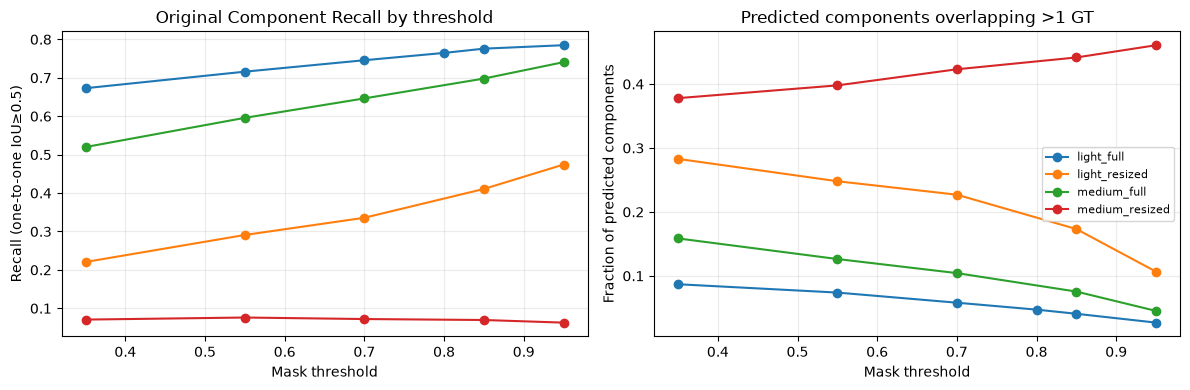

In [7]:
def topology_one(spec, index, threshold):
    gt=experiment.gt('val',index)
    pred=(experiment.score(spec,'val',index)>=np.float32(threshold))
    # Exact original segmentation evaluation, including strict one-to-one IoU>=0.5 matching.
    overview,gt_details=experiment._evaluate_mask(pred,gt,
        list(experiment.plan['size_cutoffs_px']) if experiment.plan else [100,1000],geometry=False)
    pl,npred=ndi.label(pred,structure=experiment.gt_structure)
    gl=gt['labels'];ngt=gt['n_gt']
    overlapping=(pl>0)&(gl>0)
    if overlapping.any():
        pairs=np.unique(np.stack((gl[overlapping],pl[overlapping]),axis=1),axis=0)
        per_pred=np.bincount(pairs[:,1],minlength=npred+1)[1:]
        per_gt=np.bincount(pairs[:,0],minlength=ngt+1)[1:]
        merged=int(np.count_nonzero(per_pred>1))
        fragmented=int(np.count_nonzero(per_gt>1))
    else:
        merged=fragmented=0
    # Aggregation of GT-level diagnoses uses original matching outcome, NOT a new matcher.
    d=pd.DataFrame(gt_details)
    if d.empty:
        counts=dict(gt_no_overlap=0,gt_partial_under_50=0,gt_covered_50_unmatched=0,
                    gt_matched=0,gt_covered_90_unmatched=0)
    else:
        detected_col='detected_iou_050'
        assert detected_col in d.columns, 'Expected the original matching threshold IoU=0.5'
        matched=d[detected_col].astype(bool)
        counts=dict(gt_no_overlap=int((d.coverage==0).sum()),
                    gt_partial_under_50=int(((d.coverage>0)&(d.coverage<.5)&~matched).sum()),
                    gt_covered_50_unmatched=int(((d.coverage>=.5)&~matched).sum()),
                    gt_covered_90_unmatched=int(((d.coverage>=.9)&~matched).sum()),
                    gt_matched=int(matched.sum()))
    return {'candidate':spec['variant'],'sample_id':gt['sample_id'],'pair_index':index,
            'threshold':float(threshold),'n_gt':ngt,'n_pred':npred,
            'n_pred_overlapping_multiple_gt':merged,
            'n_gt_overlapping_multiple_pred':fragmented,
            'tp':int(overview['tp']),'fp':int(overview['fp']),'fn':int(overview['fn']),
            **counts}

def validate_topology_identity(frame):
    # Every GT component is either matched or falls into exactly one unmatched coverage category.
    lhs=(frame.gt_no_overlap + frame.gt_partial_under_50 +
         frame.gt_covered_50_unmatched + frame.gt_matched)
    if not np.array_equal(lhs.to_numpy(dtype=int),frame.n_gt.to_numpy(dtype=int)):
        raise RuntimeError('Topology GT categories do not partition the ground truth!')

topo_rows=[]
if RUN_TOPOLOGY:
    for variant in TOPOLOGY_VARIANTS:
        spec=next(s for s in experiment.primary if s['variant']==variant)
        thresholds=sorted({*TOPOLOGY_THRESHOLDS,round(float(spec['saved_threshold']),4)})
        for t in thresholds:
            for i in range(len(experiment.datasets['val'])):
                topo_rows.append(topology_one(spec,i,t))
            print(f'Topology: {variant} threshold={t} complete ({len(experiment.datasets["val"])} pairs)',flush=True)
    topo=pd.DataFrame(topo_rows)
    validate_topology_identity(topo)
    topo.to_csv(OUTPUT/'09_medium_light_topology_per_pair.csv',index=False)
    group=(topo.groupby(['candidate','threshold'],as_index=False).sum(numeric_only=True))
    group['component_recall']=group.gt_matched/group.n_gt
    group['gt_covered_50_but_unmatched_fraction']=group.gt_covered_50_unmatched/group.n_gt
    group['gt_missed_fraction']=group.gt_no_overlap/group.n_gt
    group['pred_multi_gt_fraction']=group.n_pred_overlapping_multiple_gt/group.n_pred.replace(0,np.nan)
    # Pooled pixel metrics from the original evaluation counts.
    group['pixel_recall']=group.tp/(group.tp+group.fn)
    group['pixel_f1']=2*group.tp/(2*group.tp+group.fp+group.fn)
    group.to_csv(OUTPUT/'09_medium_light_topology_threshold_summary.csv',index=False)
    display(group[['candidate','threshold','pixel_f1','pixel_recall','component_recall',
                   'gt_covered_50_but_unmatched_fraction','gt_missed_fraction',
                   'pred_multi_gt_fraction']].round(4))
    fig,axes=plt.subplots(1,2,figsize=(12,4),sharex=True)
    for name,g in group.groupby('candidate'):
        axes[0].plot(g.threshold,g.component_recall,marker='o',label=name)
        axes[1].plot(g.threshold,g.pred_multi_gt_fraction,marker='o',label=name)
    axes[0].set(title='Original Component Recall by threshold',xlabel='Mask threshold',ylabel='Recall (one-to-one IoU≥0.5)')
    axes[1].set(title='Predicted components overlapping >1 GT',xlabel='Mask threshold',ylabel='Fraction of predicted components')
    for ax in axes:ax.grid(alpha=.25)
    axes[1].legend(fontsize=8)
    fig.tight_layout();fig.savefig(OUTPUT/'figures/09_topology_thresholds.png',dpi=160);plt.show()

## 6. Genuine project ROIs: recoverability, context and crop geometry

For each selected H08 configuration, call `extract_rois` with **the exact thresholds/context/min-component-area**. Analyze each real ROI bounding box and each GT component's footprint in the union of ROIs. This lets us determine whether a GT component is missed by the mask but rescued by crop extension, without equating ROI coverage with semantic correctness.

Crop-size diagnostics matter: **fewer crops does not automatically mean less work**, and many semantic models resize every crop to a fixed resolution.

Project ROI geometry complete: light_full
Project ROI geometry complete: medium_full
Project ROI geometry complete: light_resized
Project ROI geometry complete: medium_resized
ROI count/area/component-coverage reproducibility checked against H08 for every selected model.


,candidate,gt_components,raw_mask_component_coverage_50,roi_component_coverage_95,rescued_from_raw_mask_below_50,rescued_from_raw_mask_zero,n_crops,avg_crop_area,median_crop_area,p95_crop_area,multi_gt_crop_fraction,false_crop_fraction,median_gt_crop_density
0,light_full,2788,0.9042,0.9756,200,134,2842,16565.7850,16384.0,16384.00,0.8607,0.0517,0.2235
1,light_resized,2788,0.8260,0.9358,307,172,1470,19214.2075,16384.0,34955.55,0.8116,0.0667,0.1913
2,medium_full,2788,0.8902,0.9753,239,135,2201,16714.8201,16384.0,16384.00,0.8501,0.0545,0.2134
3,medium_resized,2788,0.8325,0.9397,299,135,889,31084.3555,16384.0,86288.80,0.6828,0.1642,0.1312


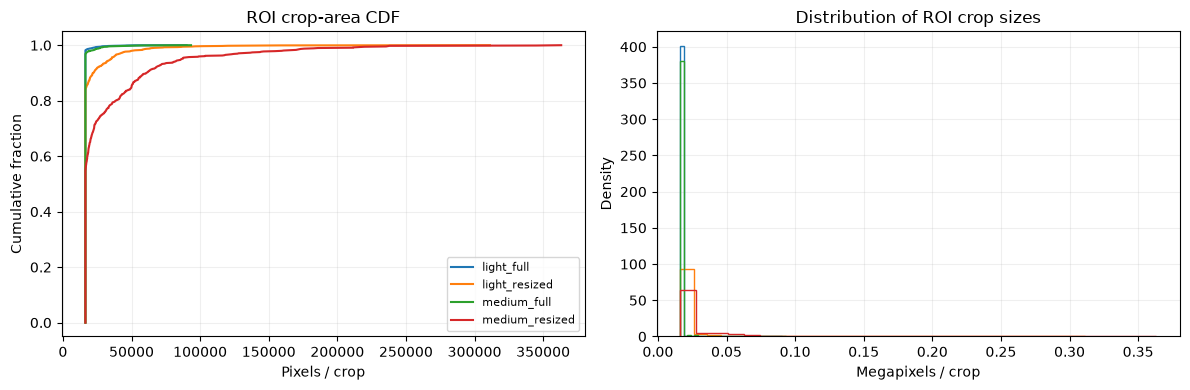

In [8]:
_DUMMY={}
def dummy_image(shape):
    if shape not in _DUMMY:_DUMMY[shape]=torch.zeros((3,*shape),dtype=torch.float32)
    return _DUMMY[shape]

def crop_geometry_for_pair(policy, index):
    gt=experiment.gt('val',index)
    spec=experiment.spec_by_id[policy.run_id]
    prob=experiment.score(spec,'val',index)
    binary=prob>=np.float32(policy.threshold)
    g=gt['mask'];gl=gt['labels'];shape=g.shape
    roi_settings=ROISettings(threshold=float(policy.threshold),connectivity=8,
        context_pixels=int(policy.context),min_crop_size=128,min_component_area=int(policy.min_area))
    before=dummy_image(shape)
    rois=extract_rois(before,before,torch.from_numpy(prob[None].astype('float32',copy=True)),settings=roi_settings)
    union=np.zeros(shape,dtype=bool)
    crops=[]
    for r in rois:
        x0,y0,x1,y1=map(int,r.crop_bbox)
        union[y0:y1,x0:x1]=True
        a=(x1-x0)*(y1-y0)
        pix=int(g[y0:y1,x0:x1].sum())
        ids=np.unique(gl[y0:y1,x0:x1]);ids=ids[ids>0]
        crops.append({'candidate':policy.candidate,'config_id':policy.config_id,
                      'pair_index':index,'sample_id':gt['sample_id'],'component_id':int(r.component_id),
                      'component_area':int(r.area),'crop_width':x1-x0,'crop_height':y1-y0,
                      'crop_area':a,'gt_pixels_in_crop':pix,'gt_pixel_density':pix/max(1,a),
                      'n_gt_components_intersected':len(ids),'is_false_crop':pix==0,
                      'one_axis_exactly_min_crop_size':(x1-x0==128 or y1-y0==128)})
    pred_pix=np.bincount(gl[binary].ravel(),minlength=gt['n_gt']+1)[1:]
    roi_pix=np.bincount(gl[union].ravel(),minlength=gt['n_gt']+1)[1:]
    sizes=np.asarray(gt['areas'][1:],dtype=float)
    gt_rows=[]
    for gid in range(1,gt['n_gt']+1):
        p_cov=float(pred_pix[gid-1]/sizes[gid-1]);roi_cov=float(roi_pix[gid-1]/sizes[gid-1])
        gt_rows.append({'candidate':policy.candidate,'config_id':policy.config_id,
                        'pair_index':index,'sample_id':gt['sample_id'],'gt_id':gid,
                        'gt_area_px':sizes[gid-1],'raw_mask_coverage':p_cov,'roi_coverage':roi_cov,
                        'roi_covered95':roi_cov>=.95,'raw_mask_covered50':p_cov>=.50,
                        'roi_rescued_from_below50':(p_cov<.50 and roi_cov>=.95),
                        'roi_rescued_from_zero':(p_cov==0 and roi_cov>=.95)})
    return crops,gt_rows,rois,union,binary,gt

crop_rows=[]; component_rows=[]
if RUN_CROP_GEOMETRY:
    for policy in choices.itertuples():
        for idx in range(len(experiment.datasets['val'])):
            rows,gt_rows,rois,mask,_,_=crop_geometry_for_pair(policy,idx)
            crop_rows.extend(rows);component_rows.extend(gt_rows)
            del rois,mask
        print('Project ROI geometry complete:',policy.candidate,flush=True)
    crop_frame=pd.DataFrame(crop_rows);component_frame=pd.DataFrame(component_rows)
    # Recheck the current ROI implementation against the actual H08 per-pair artifact,
    # including counts and the per-GT ROI-coverage threshold. No silent methodology drift.
    for policy in choices.itertuples():
        reference=validated_h08_pair_csv(policy)
        cp=(crop_frame[crop_frame.config_id==policy.config_id]
            .groupby('pair_index').agg(crop_count=('crop_area','size'),
                                      total_crop_pixels=('crop_area','sum')))
        gr=(component_frame[component_frame.config_id==policy.config_id]
            .groupby('pair_index').agg(gt_components_covered_95=('roi_covered95','sum')))
        counts=reference.set_index('pair_index')[['crop_count','total_crop_pixels','gt_components_covered_95']]
        actual=counts.index.to_frame(index=False).set_index('pair_index').join(cp).join(gr).fillna(0)
        for metric in ('crop_count','total_crop_pixels','gt_components_covered_95'):
            if not np.array_equal(actual[metric].to_numpy(dtype=np.int64),
                                  counts[metric].to_numpy(dtype=np.int64)):
                raise RuntimeError(f'ROI mismatch vs H08 for {policy.candidate}, metric={metric}. '
                                   'Check ROI source/probability caching/preprocessing settings.')
    print('ROI count/area/component-coverage reproducibility checked against H08 for every selected model.')
    crop_frame.to_csv(OUTPUT/'09_crop_geometry_per_crop.csv',index=False)
    component_frame.to_csv(OUTPUT/'09_roi_recoverability_per_gt_component.csv',index=False)
    rec=component_frame.groupby('candidate').agg(
        gt_components=('gt_id','size'),
        raw_mask_component_coverage_50=('raw_mask_covered50','mean'),
        roi_component_coverage_95=('roi_covered95','mean'),
        rescued_from_raw_mask_below_50=('roi_rescued_from_below50','sum'),
        rescued_from_raw_mask_zero=('roi_rescued_from_zero','sum')).reset_index()
    crop_summary=crop_frame.groupby('candidate').agg(
        n_crops=('crop_area','size'),avg_crop_area=('crop_area','mean'),
        median_crop_area=('crop_area','median'),p95_crop_area=('crop_area',lambda s: np.percentile(s,95)),
        multi_gt_crop_fraction=('n_gt_components_intersected',lambda s:float((s>1).mean())),
        false_crop_fraction=('is_false_crop','mean'),
        median_gt_crop_density=('gt_pixel_density','median')).reset_index()
    geometry_summary=rec.merge(crop_summary,on='candidate',how='left')
    geometry_summary.to_csv(OUTPUT/'09_crop_recoverability_summary.csv',index=False)
    display(geometry_summary.round(4))
    # Prevent 'fewer crops' from hiding a heavy tail of big crops.
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for name,gp in crop_frame.groupby('candidate'):
        vals=gp.crop_area.astype(float).to_numpy()
        axes[0].plot(np.sort(vals),np.linspace(0,1,len(vals)),label=name)
        axes[1].hist(vals/1e6,bins=30,histtype='step',density=True,label=name)
    axes[0].set(xlabel='Pixels / crop',ylabel='Cumulative fraction',title='ROI crop-area CDF')
    axes[1].set(xlabel='Megapixels / crop',ylabel='Density',title='Distribution of ROI crop sizes')
    for ax in axes:ax.grid(alpha=.2)
    axes[0].legend(fontsize=8);fig.tight_layout()
    fig.savefig(OUTPUT/'figures/09_crop_size_distributions.png',dpi=160);plt.show()

## 7. Illustrative visual case studies (real predicted masks and GT)

Automatically select the largest disagreements between raw-mask coverage and ROI coverage for **Medium Resized**. These are diagnostic examples, **not representative cases chosen at random**. Each figure shows the actual GT mask, Medium prediction and ROI boxes on the aligned prediction-mask grid; no image downloading and no resynthesized model output.

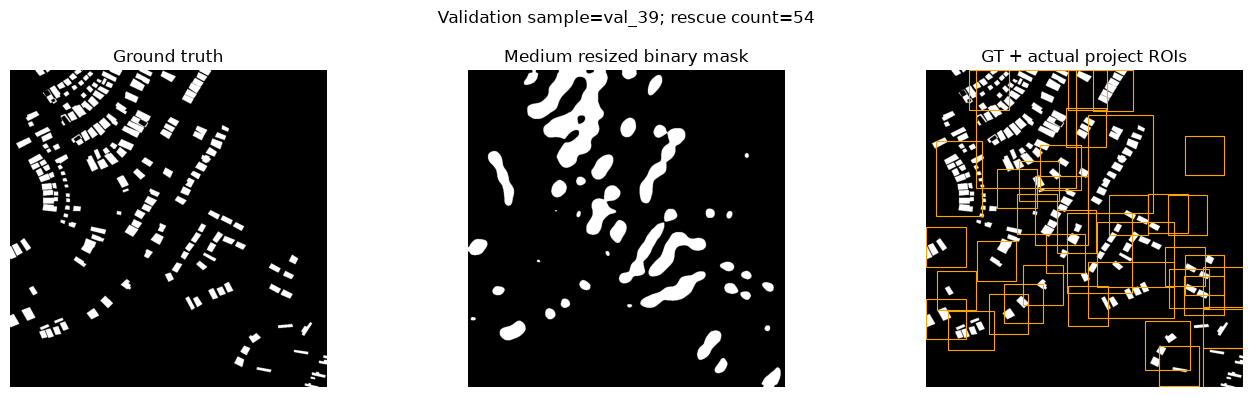

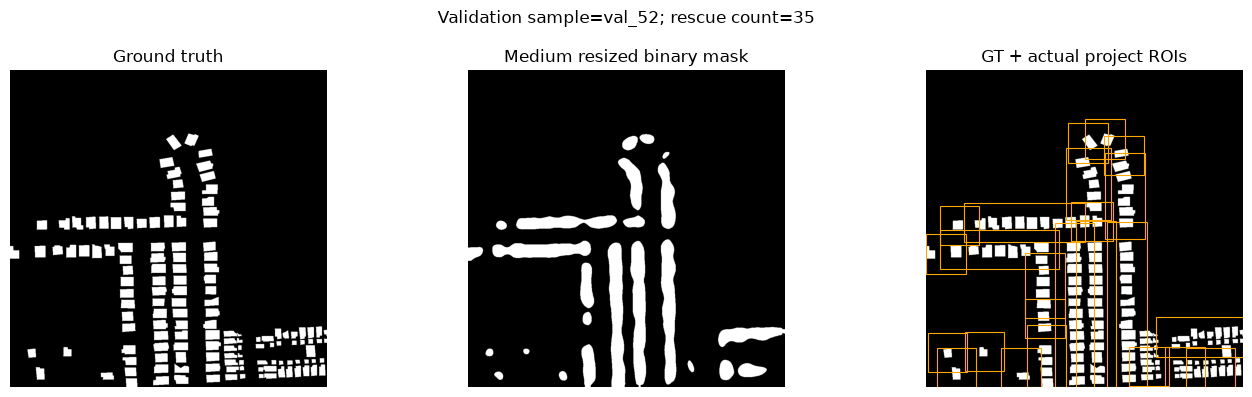

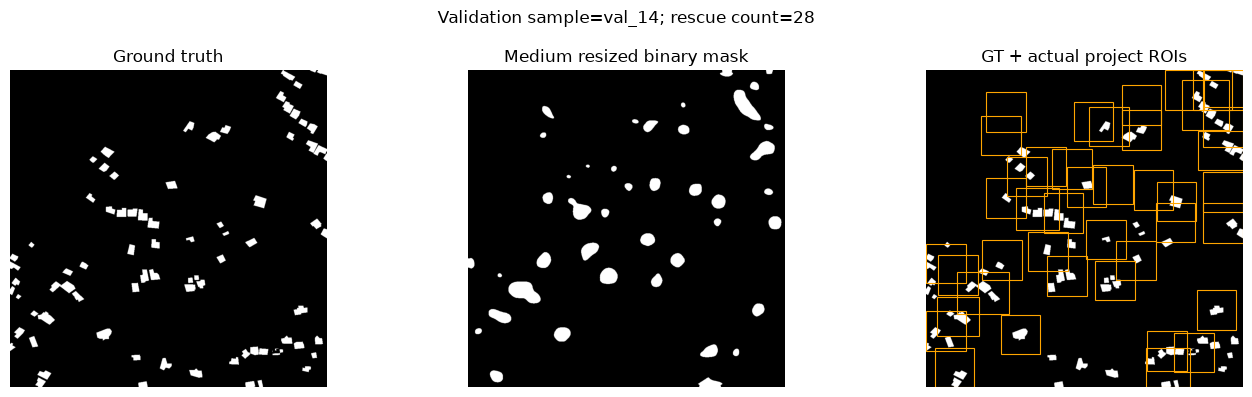

In [9]:
if RUN_CASE_STUDIES and RUN_CROP_GEOMETRY:
    medium=component_frame[component_frame.candidate=='medium_resized'].copy()
    # Case selection by largest count of components rescued from raw mask <50% coverage.
    order=(medium.groupby('pair_index').roi_rescued_from_below50.sum().sort_values(ascending=False))
    for i in order.head(N_CASE_STUDIES).index:
        policy=choices[choices.candidate=='medium_resized'].iloc[0]
        crops,gt_rows,rois,union,pred,gt=crop_geometry_for_pair(policy,int(i))
        fig,axes=plt.subplots(1,3,figsize=(14,4))
        axes[0].imshow(gt['mask'],cmap='gray',vmin=0,vmax=1)
        axes[1].imshow(pred,cmap='gray',vmin=0,vmax=1)
        axes[2].imshow(gt['mask'],cmap='gray',vmin=0,vmax=1)
        for crop in rois:
            x0,y0,x1,y1=crop.crop_bbox
            axes[2].add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,edgecolor='orange',linewidth=.8))
        for ax,title in zip(axes,('Ground truth','Medium resized binary mask','GT + actual project ROIs')):
            ax.set_title(title);ax.axis('off')
        fig.suptitle(f'Validation sample={gt["sample_id"]}; rescue count={int(order.loc[i])}');fig.tight_layout()
        fig.savefig(OUTPUT/'figures'/f'09_medium_resized_case_{i:03d}.png',dpi=140)
        plt.show();plt.close(fig)
        del rois,union

## 8. Downstream cost sensitivity — not an actual WHAT benchmark

Using the complete H08 single-model policy grid, assess illustrative cost assumptions:

`total_ms = measured_WHERE_forward_ms + crop_count × assumed_ms_per_crop + total_crop_megapixels × assumed_ms_per_megapixel`

These are *not measured end-to-end timings*. The objective is to identify which WHAT latency ranges would make Medium vs Light promising enough to carry into SECOND. Actual cost must be measured after implementing WHAT inference, including batching and preprocessing.

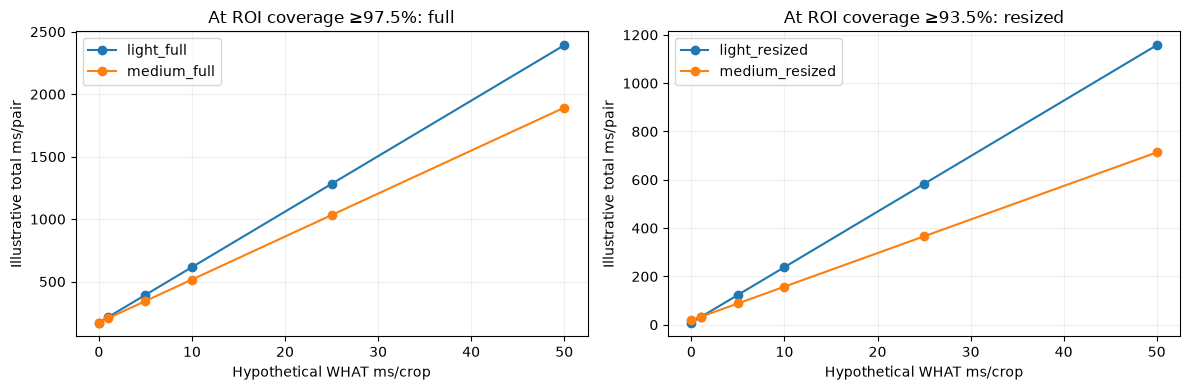

,candidate,required_component_coverage_95,coverage_95,crops_per_pair,illustrative_total_ms
65,medium_resized,0.900,0.908,12.922,147.863
61,heavy_resized,0.900,0.954,16.781,213.637
63,light_resized,0.900,0.936,22.969,238.470
64,medium_full,0.900,0.965,31.734,490.029
62,light_full,0.900,0.970,37.750,549.105
60,heavy_full,0.900,0.981,38.547,662.604
173,medium_resized,0.935,0.940,13.891,157.742
169,heavy_resized,0.935,0.954,16.781,213.637
171,light_resized,0.935,0.936,22.969,238.470
172,medium_full,0.935,0.965,31.734,490.029


In [10]:
scenario_rows=[]
if RUN_COST_SENSITIVITY:
    h08_cost=scenario_configs.drop_duplicates('config_id').copy()
    h08_cost=h08_cost[h08_cost.kind=='single']
    # 1024x1024 native LEVIR image; obtain actual size from GT (don't guess).
    image=experiment.gt('val',0)['mask'];native_mpix=image.size/1e6
    for crop_ms in DOWNSTREAM_MS_PER_CROP:
        for mpix_ms in DOWNSTREAM_MS_PER_MPIXEL:
            for row in h08_cost.itertuples():
                estimated=float(row.detector_forward_ms)+crop_ms*float(row.crops_per_pair)+\
                    mpix_ms*float(row.total_processed_fraction)*native_mpix
                scenario_rows.append(dict(candidate=row.candidate,config_id=row.config_id,
                    coverage_95=row.roi_component_coverage_95,crops_per_pair=row.crops_per_pair,
                    processed_image_fraction=row.total_processed_fraction,
                    where_forward_ms=row.detector_forward_ms,assumed_per_crop_ms=crop_ms,
                    assumed_per_crop_mpix_ms=mpix_ms,illustrative_total_ms=estimated))
    sensitivity=pd.DataFrame(scenario_rows)
    sensitivity.to_csv(OUTPUT/'09_downstream_cost_sensitivity_all_configs.csv',index=False)
    # For a fixed and clearly stated coverage target, choose best cost per variant.
    selected=[]
    for target in (.90,.935,.95,.975,.98):
        for (cm,pm),g in sensitivity.groupby(['assumed_per_crop_ms','assumed_per_crop_mpix_ms']):
            eligible=g[g.coverage_95>=target]
            for variant,items in eligible.groupby('candidate'):
                best=items.sort_values(['illustrative_total_ms','config_id']).iloc[0]
                selected.append({**best.to_dict(),'required_component_coverage_95':target})
    sensitivity_selected=pd.DataFrame(selected)
    sensitivity_selected.to_csv(OUTPUT/'09_cost_sensitivity_best_by_coverage.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for j,(family,target) in enumerate([('full',.975),('resized',.935)]):
        pp=sensitivity_selected[(sensitivity_selected.required_component_coverage_95==target)&
               (sensitivity_selected.assumed_per_crop_mpix_ms==2.0)]
        for variant in (f'light_{family}',f'medium_{family}'):
            dat=pp[pp.candidate==variant].sort_values('assumed_per_crop_ms')
            if dat.empty:continue
            axes[j].plot(dat.assumed_per_crop_ms,dat.illustrative_total_ms,marker='o',label=variant)
        axes[j].set(title=f'At ROI coverage ≥{target:.1%}: {family}',
                    xlabel='Hypothetical WHAT ms/crop',ylabel='Illustrative total ms/pair')
        axes[j].grid(alpha=.2);axes[j].legend()
    fig.tight_layout();fig.savefig(OUTPUT/'figures/09_cost_sensitivity.png',dpi=160);plt.show()
    display(sensitivity_selected[(sensitivity_selected.assumed_per_crop_ms==10.0)&
          (sensitivity_selected.assumed_per_crop_mpix_ms==2.0)][
        ['candidate','required_component_coverage_95','coverage_95','crops_per_pair',
         'illustrative_total_ms']].round(3).sort_values(['required_component_coverage_95','illustrative_total_ms']))

## 9. Decision audit — how to interpret this study

Write conclusions **after inspecting outputs**, not as a hardcoded verdict. Evidence for a *pipeline ROI advantage* does **not** imply evidence for better segmentation training. This decision table lists what we can and cannot identify with already-trained checkpoints.

In [11]:
decision_rows=[
    {'question':'Is Medium instability due to one unlucky seed?',
     'evidence':'H08 all-three-seed validation F1/Component Recall/ROI coverage',
     'identified':'Variation across saved seeds; not training hyperparameter causation'},
    {'question':'Are many Medium changes covered but unmatched?',
     'evidence':'09 topology per-pair, original matching and GT overlap counts',
     'identified':'Overlap, merges and threshold sensitivity; not root cause of training'},
    {'question':'Do ROI margins rescue missed parts?',
     'evidence':'09 per-GT raw-mask vs ROI coverage',
     'identified':'Number and area of changes rescued by crop geometry; not semantic accuracy'},
    {'question':'Is Medium less costly than Light at similar ROI coverage?',
     'evidence':'09 coverage-target choices, paired CIs and sensitivity curves',
     'identified':'LEVIR validation under declared cost assumptions; not final SECOND performance'},
    {'question':'Should we retrain Medium?',
     'evidence':'Combined topology, ROI performance and later SECOND domain adaptation',
     'identified':'Only priority of retraining; to attribute causality perform controlled HPO/retraining'},
]
decision=pd.DataFrame(decision_rows)
decision.to_csv(OUTPUT/'09_decision_scope.csv',index=False)
display(decision)

,question,evidence,identified
0,Is Medium instability due to one unlucky seed?,H08 all-three-seed validation F1/Component Rec...,Variation across saved seeds; not training hyp...
1,Are many Medium changes covered but unmatched?,"09 topology per-pair, original matching and GT...","Overlap, merges and threshold sensitivity; not..."
2,Do ROI margins rescue missed parts?,09 per-GT raw-mask vs ROI coverage,Number and area of changes rescued by crop geo...
3,Is Medium less costly than Light at similar RO...,"09 coverage-target choices, paired CIs and sen...",LEVIR validation under declared cost assumptio...
4,Should we retrain Medium?,"Combined topology, ROI performance and later S...",Only priority of retraining; to attribute caus...


## 10. Export all results to one shareable ZIP

In [12]:
manifest={
 'run':OUT_NAME,'created_utc':datetime.now(timezone.utc).isoformat(),
 'validation_only':True,'uses_test':False,'retraining':False,
 'source_v1_signature':experiment.signature,
 'original_06_core_sha256':core_sha,
 'roi_module_sha256':roi_sha,
 'h08_source_run':H08_RUN,
 'target_coverage':TARGET_COVERAGE,'match_tolerance':MATCH_TOLERANCE,
 'thresholds':list(TOPOLOGY_THRESHOLDS),'bootstrap_reps':BOOTSTRAP_REPS,
 'cost_scope':'H08 detector forward-only milliseconds + explicitly hypothetical crop/Mpixel costs',
 'complete_flags':{
  'topology':RUN_TOPOLOGY,'crop_geometry':RUN_CROP_GEOMETRY,
  'matched_comparisons':RUN_MATCHED_COMPARISONS,'cost_sensitivity':RUN_COST_SENSITIVITY,
  'case_studies':RUN_CASE_STUDIES},
 'source_note':'Only original V1 validation caches. No second-stage semantic inference in this notebook.',
}
(OUTPUT/'09_run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
result_zip=OUTPUT/(OUT_NAME+'_results.zip')
with zipfile.ZipFile(result_zip,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUTPUT.rglob('*')):
        if p.is_file() and p!=result_zip and p.suffix.lower() in ('.csv','.png','.json'):
            z.write(p,p.relative_to(OUTPUT).as_posix())
print('Result archive:',result_zip,'(MB)',round(result_zip.stat().st_size/1048576,2))
display(FileLink(str(result_zip)))

Result archive: artifacts/hypothesis_tests/H09_medium_topology_matched_cost/H09_medium_topology_matched_cost_results.zip (MB) 0.89


artifacts/hypothesis_tests/H09_medium_topology_matched_cost/H09_medium_topology_matched_cost_results.zip